# Kompletny przewodnik: standaryzacja i przygotowanie cech (Pandas, Polars, scikit-learn)

Przewodnik referencyjny (Python 3.10+, pandas, polars ≥ 1.0, scikit-learn ≥ 1.3). Odpowiada na pytania: **jak** przekształcać dane, **kiedy** (ML a codzienna analiza), **czy wszystkie kolumny traktować tak samo** (nie) i **jak to sprawdzić automatycznie** (sekcja 9: kod, który dla każdej kolumny zwraca rekomendację i uzasadnienie).

Kod jest „inline" (bez opakowywania w funkcje), każda komórka jest samodzielna po wykonaniu sekcji **0**. W tabelach parametrów ✅ = wymagany, ⬜ = opcjonalny. Każdy element zaczyna się od **wersji podstawowej** (minimum kodu), potem są parametry i warianty. Dla większości operacji podaję trzy implementacje: **pandas**, **Polars**, **scikit-learn**.

**Spis treści**

0. Setup i dane przykładowe (wszystkie typy kolumn)
1. Terminologia: standaryzacja, normalizacja, skalowanie, transformacja, kodowanie
2. Czy skalować? Zależy od modelu i celu (ML vs analiza)
3. Zasada nr 1: wyciek danych (*data leakage*), `Pipeline`, `ColumnTransformer`
4. Cechy ciągłe: z-score, min-max, robust, max-abs, normalizacja wierszy
5. Skośność i wartości odstające: log, Box-Cox, Yeo-Johnson, kwantylowa, winsoryzacja, dyskretyzacja
6. Pozostałe typy liczbowe: binarne, liczniki, odsetki, kwoty z ujemnymi, skale porządkowe, współrzędne
7. Kategorie, daty, tekst, liczby zapisane jako tekst, braki danych
8. Standaryzacja w analizie: grupy, indeksy, rangi, wskaźniki
9. **Doradca standaryzacji: jeden kod dla wszystkich kolumn** (rekomendacja + uzasadnienie + automatyczny `ColumnTransformer`)
10. Ściągawka i typowe błędy

## 0. Setup i dane przykładowe

In [55]:
import re
import warnings
import numpy as np
import pandas as pd
import polars as pl
import scipy.stats as st
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer, make_column_transformer, make_column_selector, TransformedTargetRegressor
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, RobustScaler, MaxAbsScaler, Normalizer,
                                   PowerTransformer, QuantileTransformer, FunctionTransformer, KBinsDiscretizer,
                                   OneHotEncoder, OrdinalEncoder, TargetEncoder, SplineTransformer)
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
print(sklearn.__version__, pl.__version__, pd.__version__)

1.9.1 1.41.2 3.0.6


### Dane: klienci sklepu internetowego (każdy typ kolumny występuje przynajmniej raz)

| Kolumna | Typ | Co testuje |
|---|---|---|
| `customer_id` | identyfikator tekstowy | nigdy nie skalować; usuń z cech |
| `signup_date`, `last_login` | data / data-czas | cechy z dat, wiek konta |
| `age` | liczba ~ symetryczna, braki | z-score |
| `income` | dodatnia, silnie skośna | log / Yeo-Johnson |
| `income_outliers` | jak wyżej + ekstremalne wartości | skalowanie odporne, winsoryzacja |
| `balance` | z ujemnymi, duży rozrzut | Yeo-Johnson / signed log |
| `profit` | ciężkie ogony, ujemne | robust / Yeo-Johnson |
| `n_orders` | licznik (0, 1, 2…) | log1p / bez zmian dla drzew |
| `discount_rate`, `conversion_rate` | odsetek 0–1 | bez skalowania / logit |
| `satisfaction` | skala porządkowa 1–5, braki | traktowanie porządkowe |
| `region`, `channel` | kategorie nominalne | one-hot |
| `city` | kategoria o wysokiej kardynalności (150) | kodowanie częstością / target encoding |
| `segment` | kategoria uporządkowana | kodowanie porządkowe |
| `is_returning`, `newsletter` | binarne (bool / 0-1) | bez skalowania |
| `country`, `tier_code` | stała / prawie stała | usunąć |
| `lat`, `lon` | współrzędne | nie standaryzować osobno |
| `hour`, `weekday`, `order_month` | cykliczne | kodowanie sin/cos |
| `name_raw`, `email` | brudny tekst | czyszczenie |
| `revenue_text`, `pct_text`, `signup_text` | liczby/daty zapisane jako tekst | parsowanie |
| `comment` | tekst swobodny | TF-IDF lub pominąć |
| `revenue` | **cel** (regresja, skośny) | transformacja celu |
| `churn` | **cel** (klasyfikacja 0/1) | bez skalowania |

In [56]:
rng = np.random.default_rng(42)
n = 2000

signup = pd.Timestamp("2020-01-01") + pd.to_timedelta(rng.integers(0, 365 * 5, n), unit="D")
age = np.clip(rng.normal(40, 12, n), 18, 80).round()
income = (rng.lognormal(10.3, 0.5, n) * (1 + (age - 18) / 100)).round(0)
income_outliers = income.copy()
income_outliers[rng.choice(n, 20, replace=False)] *= rng.uniform(8, 15, 20)               # 1% ekstremalnych
satisfaction = np.clip(np.round(rng.normal(3.8, 1.0, n)), 1, 5)
n_orders = rng.poisson(4, n)
discount_rate = np.clip(rng.beta(2, 12, n), 0, 0.5).round(3)

df = pd.DataFrame({
    "customer_id": [f"C{i:05d}" for i in range(n)],
    "signup_date": signup,
    "last_login": signup + pd.to_timedelta(rng.integers(0, 24 * 60 * 24 * 365, n), unit="min"),
    "age": age,
    "income": income,
    "income_outliers": income_outliers,
    "balance": rng.normal(2000, 4000, n).round(2),
    "profit": (rng.standard_t(3, n) * 300 + 150).round(2),
    "n_orders": n_orders,
    "discount_rate": discount_rate,
    "conversion_rate": rng.beta(2, 30, n).round(4),
    "satisfaction": satisfaction,
    "region": rng.choice(["Północ", "Południe", "Wschód", "Zachód", "Centrum"], n, p=[.2, .15, .2, .2, .25]),
    "channel": rng.choice(["Online", "Sklep", "Telefon"], n, p=[.55, .35, .10]),
    "city": [f"Miasto_{i:03d}" for i in rng.integers(0, 150, n)],
    "segment": pd.Categorical(rng.choice(["Basic", "Standard", "Premium"], n, p=[.45, .40, .15]),
                              categories=["Basic", "Standard", "Premium"], ordered=True),
    "is_returning": rng.random(n) < 0.4,
    "newsletter": rng.integers(0, 2, n),
    "country": "PL",
    "tier_code": rng.choice(["A", "B"], n, p=[.995, .005]),
    "lat": rng.uniform(49.0, 54.8, n).round(4),
    "lon": rng.uniform(14.2, 24.1, n).round(4),
    "hour": rng.integers(0, 24, n),
    "weekday": rng.integers(0, 7, n),
    "order_month": rng.integers(1, 13, n),
})

# --- brudny tekst
first = rng.choice(["jan", "ANNA", "Piotr", "  maria", "KATARZYNA ", "tomasz"], n)
last = rng.choice(["Kowalski", "NOWAK", "wiśniewska", "Wójcik ", " Kamiński", "Łukasiewicz"], n)
df["name_raw"] = [f"{f} {l}" if rng.random() > 0.2 else f"{f}   {l}" for f, l in zip(first, last)]
df["email"] = [(f"{f.strip()}.{l.strip()}{i}@Example.pl").lower().replace("ł", "l").replace("ó", "o").replace("ś", "s").replace("ń", "n") if rng.random() > .3 else f"{f.strip()}.{l.strip()}{i}@EXAMPLE.PL".upper()
               for i, (f, l) in enumerate(zip(first, last))]
words = np.array(["szybka", "dostawa", "świetny", "produkt", "wolna", "obsługa", "polecam", "drogo", "jakość", "opóźnienie", "wszystko", "dobrze", "zwrot", "reklamacja"])
df["comment"] = [" ".join(rng.choice(words, rng.integers(3, 8))) for _ in range(n)]

# --- cele (targetów NIE standaryzujemy jak cech)
df["revenue"] = ((df["n_orders"] + 1) * rng.lognormal(4.5, 0.6, n) * (1 + df["discount_rate"])).round(2)           # skośny, dodatni
logit = -0.4 - 0.04 * (age - 40) - 0.55 * (satisfaction - 3.8) - 0.15 * (n_orders - 4) + 0.5 * (df["channel"] == "Online").to_numpy()
df["churn"] = (rng.random(n) < 1 / (1 + np.exp(-logit))).astype(int)

# --- liczby i daty zapisane jako tekst (typowe w plikach z Excela/CSV)
df["revenue_text"] = [f"{v:,.2f}".replace(",", " ").replace(".", ",") + (" zł" if rng.random() > .5 else "\u00a0PLN") for v in df["revenue"]]
df["pct_text"] = [f"{v * 100:.1f}%".replace(".", ",") for v in df["discount_rate"]]
df["signup_text"] = df["signup_date"].dt.strftime("%d.%m.%Y")

# --- braki danych
for col, share in {"age": 0.05, "income": 0.03, "satisfaction": 0.08, "region": 0.02}.items():
    df.loc[rng.choice(n, int(n * share), replace=False), col] = np.nan

df_raw = df.copy()                   # surowa kopia (bez kolumn pochodnych) do doradcy z sekcji 9
df_pl = pl.from_pandas(df)           # ta sama ramka w Polars (do porównań składni)
target_cols = ["revenue", "churn"]
print(df.shape)
df.head(3).T

(2000, 33)


,0,1,2
customer_id,C00000,C00001,C00002
signup_date,2020-06-11 00:00:00,2023-11-13 00:00:00,2023-04-09 00:00:00
last_login,2027-05-09 14:22:00,2042-09-18 11:47:00,2042-03-27 16:20:00
age,31.0,51.0,NaN
income,23895.0,109194.0,35690.0
income_outliers,23895.0,109194.0,35690.0
balance,2125.08,-1414.92,3784.31
profit,306.43,-483.38,458.08
n_orders,2,4,6
discount_rate,0.211,0.269,0.049


## 1. Terminologia

W praktyce słowa „standaryzacja" i „normalizacja" są używane zamiennie, więc warto je rozdzielić.

| Pojęcie | Co robi | Przykład | Zmienia kształt rozkładu? |
|---|---|---|---|
| **Standaryzacja** (*standardization*, z-score) | Średnia 0, odchylenie 1: `(x − μ) / σ` | `StandardScaler` | Nie (tylko przesunięcie i skala) |
| **Normalizacja min-max** | Przeskalowanie do przedziału (zwykle [0, 1]): `(x − min) / (max − min)` | `MinMaxScaler` | Nie |
| **Skalowanie odporne** | Mediana 0, rozstęp międzykwartylowy 1: `(x − Q2) / IQR` | `RobustScaler` | Nie |
| **Normalizacja wierszy** | Wektor każdego **wiersza** ma długość 1 (L1/L2) | `Normalizer` | Nie |
| **Transformacja rozkładu** | Zmienia kształt (zmniejsza skośność, ogony) | `log1p`, Box-Cox, Yeo-Johnson, `QuantileTransformer` | **Tak** |
| **Dyskretyzacja** | Zamiana ciągłej na przedziały | `KBinsDiscretizer`, `pd.cut` | Tak |
| **Kodowanie** (*encoding*) | Kategorie → liczby | `OneHotEncoder`, `OrdinalEncoder`, `TargetEncoder` | n/d |
| **Czyszczenie / standaryzacja formatu** | Ujednolicenie zapisu (spacje, wielkość liter, jednostki, daty) | `.str.strip().str.lower()` | n/d |
| **Imputacja** | Uzupełnianie braków | `SimpleImputer`, `fillna` | Może |

### Odpowiedź na pytanie: czy wszystkie kolumny standaryzować tak samo?

**Nie.** Sposób zależy od czterech rzeczy:

1. **Typ i skala pomiarowa kolumny:** liczba ciągła, licznik, odsetek, binarna, porządkowa, nominalna, data, współrzędna, identyfikator, tekst. Każdy typ ma inne „bezpieczne" przekształcenia (np. nominalnej nie skaluje się, a identyfikatora nie używa się wcale).
2. **Kształt rozkładu i wartości odstające:** skośne dodatnie (kwoty, czasy) zwykle wymagają logarytmu; z outlierami rozsądniejszy jest `RobustScaler` niż z-score.
3. **Cel i model:** modele odległościowe i gradientowe (KNN, SVM, regresja z regularyzacją, sieci, PCA, k-means) potrzebują porównywalnych skal; modele drzewiaste (Random Forest, XGBoost, LightGBM) w ogóle ich nie potrzebują (sekcja 2).
4. **Zastosowanie: ML czy analiza.** W modelu liczy się zachowanie algorytmu. W raporcie liczy się **interpretowalność** (jednostki, procenty, indeks 100), a nie z-score (sekcja 8).

> **Zasada praktyczna:** każdą kolumnę najpierw **klasyfikujesz** (jakiego jest typu i jaki ma rozkład), a dopiero potem dobierasz przekształcenie. Sekcja 9 automatyzuje ten krok.

## 2. Czy skalować? Zależy od modelu i celu

| Algorytm | Czy wymaga skalowania cech? | Dlaczego |
|---|---|---|
| Regresja liniowa (bez regularyzacji) | Nie (dla predykcji); **tak** dla porównania współczynników | Skala zmienia współczynniki, nie dopasowanie |
| **Regresja z regularyzacją** (Ridge, Lasso, ElasticNet), logistyczna z `penalty` | **Tak** | Kara dotyka współczynników zależnie od skali cechy |
| **KNN, SVM (RBF), k-means, DBSCAN, hierarchiczne** | **Tak, krytycznie** | Opierają się na odległościach; cecha o dużej skali dominuje |
| **PCA, LDA, analiza czynnikowa** | **Tak** | Wariancja zależy od jednostek |
| **Sieci neuronowe, gradient descent** | **Tak** | Szybsza i stabilniejsza zbieżność |
| **Drzewa, Random Forest, Gradient Boosting (XGBoost, LightGBM, HistGB)** | **Nie** | Dzielą wartości progiem; zmiana skali nie zmienia podziałów |
| Naive Bayes (Gaussian) | Nie wymagane | Estymuje parametry osobno dla cech |
| Modele z interakcjami/wielomianami | Zalecane | Stabilność numeryczna |

Kolejność korzyści: **skalowanie nie szkodzi drzewom** (tylko nie pomaga), a **bez skalowania psuje modele odległościowe**. Dlatego w pipeline'ach uniwersalnych skalowanie zwykle dodaje się, a przy modelach drzewiastych można je pominąć, żeby wynik pozostał w oryginalnych jednostkach (łatwiejsza interpretacja).

### Eksperyment: ten sam model z i bez skalowania

In [57]:
num_cols_exp = ["age", "income", "balance", "n_orders", "discount_rate", "profit"]
X = df[num_cols_exp]
y = df["churn"]
cv = StratifiedKFold(5, shuffle=True, random_state=0)
impute = SimpleImputer(strategy="median")                                # braki uzupełniamy w każdym wariancie tak samo

models = {
    "KNN": KNeighborsClassifier(n_neighbors=25),
    "Regresja logistyczna": LogisticRegression(C=0.1, max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1),
}
rows = []
for name, model in models.items():
    raw = cross_val_score(make_pipeline(impute, model), X, y, cv=cv, scoring="roc_auc").mean()
    scaled = cross_val_score(make_pipeline(impute, StandardScaler(), model), X, y, cv=cv, scoring="roc_auc").mean()
    rows.append({"model": name, "AUC bez skalowania": round(raw, 3), "AUC ze StandardScaler": round(scaled, 3), "różnica": round(scaled - raw, 3)})
pd.DataFrame(rows)

,model,AUC bez skalowania,AUC ze StandardScaler,różnica
0,KNN,0.511,0.617,0.105
1,Regresja logistyczna,0.632,0.630,-0.002
2,Random Forest,0.598,0.598,-0.000


**Interpretacja:** dla KNN i regresji z regularyzacją skalowanie wyraźnie zmienia wynik (cecha `income`/`balance` o skali rzędu tysięcy zdominowałaby odległość). Dla Random Forest różnica jest bliska zera, bo drzewa są niewrażliwe na skalę.

## 3. Zasada nr 1: wyciek danych, `Pipeline` i `ColumnTransformer`

**Wyciek danych (*data leakage*):** jeżeli średnią, odchylenie, kwantyle lub średnie z celu policzysz na **całym** zbiorze (także na części testowej), model „widzi" informację z przyszłości, a metryki są zawyżone. Wszystkie przekształcenia, które **uczą się** z danych (`fit`), muszą być dopasowane **tylko na zbiorze treningowym**, a potem zastosowane (`transform`) do testowego i produkcyjnego.

| Przekształcenie | Uczy się z danych? | Wymaga fit na train? |
|---|---|---|
| `StandardScaler`, `MinMaxScaler`, `RobustScaler`, `PowerTransformer`, `QuantileTransformer` | Tak (μ, σ, min/max, kwantyle, λ) | **Tak** |
| `SimpleImputer`, `KNNImputer` | Tak (mediana, sąsiedzi) | **Tak** |
| `OneHotEncoder`, `OrdinalEncoder`, kodowanie częstością | Tak (lista kategorii/częstości) | **Tak** |
| `TargetEncoder`, każde kodowanie wg celu | Tak (**używa celu**) | **Tak, z walidacją krzyżową wewnątrz** |
| `np.log1p`, `abs`, `sin`/`cos` cykliczne, cechy z dat, czyszczenie tekstu | Nie (funkcje deterministyczne) | Nie |

#### Wersja podstawowa (scikit-learn): `fit` na train, `transform` na test

In [58]:
X_train, X_test, y_train, y_test = train_test_split(df[["age", "income"]].fillna(df[["age", "income"]].median()), df["churn"],
                                                    test_size=0.25, random_state=42, stratify=df["churn"])
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)          # uczy się μ, σ z TRAIN i przekształca TRAIN
X_test_s = scaler.transform(X_test)                # używa μ, σ z TRAIN (nie liczy nowych!)

print("średnie train:", X_train_s.mean(axis=0).round(3), "| średnie test:", X_test_s.mean(axis=0).round(3))     # test ≠ 0: to normalne

średnie train: [0. 0.] | średnie test: [-0.005 -0.02 ]


#### To samo w pandas i Polars (statystyki z train zapisane ręcznie)

In [59]:
# pandas
mu, sd = X_train.mean(), X_train.std(ddof=0)       # ddof=0 = tak jak scikit-learn (patrz sekcja 4.1)
X_test_pd = (X_test - mu) / sd

# Polars
train_pl = pl.from_pandas(X_train.reset_index(drop=True))
test_pl = pl.from_pandas(X_test.reset_index(drop=True))
stats = train_pl.select([pl.col(c).mean().alias(f"{c}_mu") for c in train_pl.columns] +
                        [pl.col(c).std(ddof=0).alias(f"{c}_sd") for c in train_pl.columns]).row(0, named=True)
test_pl_s = test_pl.with_columns([((pl.col(c) - stats[f"{c}_mu"]) / stats[f"{c}_sd"]).alias(c) for c in test_pl.columns])
print(np.allclose(X_test_pd.to_numpy(), test_pl_s.to_numpy()), np.allclose(X_test_pd.to_numpy(), X_test_s))

True True


### 3.1. Dlaczego `Pipeline`: walidacja krzyżowa bez wycieku

W `cross_val_score` przekształcenia muszą być **wewnątrz** pipeline'u, wtedy w każdym foldzie są dopasowywane tylko do jego części treningowej.

In [60]:
X = df[["age", "income", "balance", "n_orders"]]

# źle: skaler na całym zbiorze przed walidacją (subtelny wyciek)
X_leaky = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(X))
auc_leaky = cross_val_score(LogisticRegression(max_iter=1000), X_leaky, y, cv=cv, scoring="roc_auc").mean()

# dobrze: wszystko w pipeline
pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000))
auc_ok = cross_val_score(pipe, X, y, cv=cv, scoring="roc_auc").mean()
print(f"z wyciekiem: {auc_leaky:.4f} | w pipeline: {auc_ok:.4f}")

z wyciekiem: 0.6310 | w pipeline: 0.6310


Przy skalerach różnica jest zwykle mała. **Dramatyczny wyciek** powstaje przy kodowaniu wg celu (target encoding), selekcji cech i imputacji opartej o cel. Poniżej: kolumna `city` (150 miast) **losowa i niezwiązana z odejściem klientów**, a „model" po kodowaniu średnią z celu liczoną na całym zbiorze „odkrywa" zależność, której nie ma.

In [61]:
# źle: średnia celu per miasto policzona na CAŁYM zbiorze (używa y przed podziałem na foldy)
city_te_leaky = df.groupby("city")["churn"].transform("mean").to_frame("city_te")
auc_leaky = cross_val_score(LogisticRegression(), city_te_leaky, y, cv=cv, scoring="roc_auc").mean()

# dobrze: TargetEncoder w pipeline (wewnętrznie używa walidacji krzyżowej do kodowania treningu)
pipe_te = make_pipeline(TargetEncoder(smooth="auto", cv=5, random_state=0), LogisticRegression())
auc_ok = cross_val_score(pipe_te, df[["city"]], y, cv=cv, scoring="roc_auc").mean()
print(f"kodowanie z wyciekiem: AUC = {auc_leaky:.3f} (pozorna zależność) | poprawne: AUC = {auc_ok:.3f} (≈ 0.5 = brak informacji)")

C:\Users\pkawk\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
C:\Users\pkawk\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
C:\Users\pkawk\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\sit

kodowanie z wyciekiem: AUC = 0.663 (pozorna zależność) | poprawne: AUC = 0.497 (≈ 0.5 = brak informacji)


### 3.2. `ColumnTransformer`: inne przekształcenie dla każdej grupy kolumn

To odpowiedź techniczna na pytanie „czy wszystkie kolumny tak samo": **nie**, a `ColumnTransformer` stosuje różne transformatory do różnych kolumn w jednym obiekcie, który można zapisać i użyć w produkcji.

| Parametr `ColumnTransformer` | Opis |
|---|---|
| `transformers` ✅ | Lista krotek `(nazwa, transformator, kolumny)`; kolumny jako lista nazw, `make_column_selector(...)` lub maska |
| `remainder` ⬜ | Co z pozostałymi kolumnami: `"drop"` (domyślnie), `"passthrough"` lub transformator |
| `verbose_feature_names_out` ⬜ | `False` = nazwy wynikowych kolumn bez prefiksu transformatora |
| `sparse_threshold` ⬜ | Próg gęstości, poniżej którego zwraca macierz rzadką |
| `n_jobs` ⬜ | Równoległość |
| `.set_output(transform="pandas")` | Wynik jako DataFrame z nazwami kolumn (lub `"polars"`) |

#### Wersja podstawowa

In [62]:
ct = ColumnTransformer([
    ("num", StandardScaler(), ["age", "balance"]),                       # liczby: z-score
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["region", "channel"]),   # kategorie: one-hot
], remainder="drop").set_output(transform="pandas")

# braki: imputujemy w pipeline (ColumnTransformer nie ma wbudowanego uzupełniania)
Xt = ct.fit_transform(df[["age", "balance", "region", "channel"]].assign(age=lambda d: d["age"].fillna(d["age"].median()),
                                                                           region=lambda d: d["region"].fillna("brak")))
Xt.head(3)

,num__age,num__balance,cat__region_Centrum,cat__region_Południe,cat__region_Północ,cat__region_Wschód,cat__region_Zachód,cat__region_brak,cat__channel_Online,cat__channel_Sklep,cat__channel_Telefon
0,-0.780733,-0.007598,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.962169,-0.873039,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,0.003573,0.398042,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0


Pełny, kompletny `ColumnTransformer` z imputacją i osobnym traktowaniem każdej grupy zbudujemy w sekcjach 7 i 9.

## 4. Cechy ciągłe: z-score, min-max, robust, max-abs, normalizacja wierszy

### 4.1. Standaryzacja z-score (`StandardScaler`)

**Co robi:** `z = (x − μ) / σ`. Po przekształceniu średnia = 0, odchylenie = 1. Jednostką jest „liczba odchyleń od średniej".
**Kiedy:** cechy ciągłe o rozkładzie zbliżonym do symetrycznego, bez silnych outlierów; modele z regularyzacją, KNN, SVM, PCA, sieci. W analizie: porównanie **różnych miar** w jednej skali (np. wynik sprzedaży vs. satysfakcja) lub wykrywanie nietypowych obserwacji (|z| > 3).
**Kiedy nie:** rozkład silnie skośny lub z outlierami (średnia i σ są wtedy zniekształcone, więc zob. 4.3 i 5); cechy binarne, kategorie, identyfikatory.

#### Wersja podstawowa

In [63]:
# scikit-learn (wymaga 2D: DataFrame/macierz, nie Series)
scaler = StandardScaler()
df["age_z_sk"] = scaler.fit_transform(df[["age"]])                 # braki (NaN) są ignorowane w fit i zostają NaN
print(scaler.mean_, scaler.scale_)                                  # μ i σ nauczone z danych

# pandas
df["age_z_pd"] = (df["age"] - df["age"].mean()) / df["age"].std(ddof=0)

# Polars
df_pl = df_pl.with_columns(((pl.col("age") - pl.col("age").mean()) / pl.col("age").std(ddof=0)).alias("age_z_pl"))

print(np.allclose(df["age_z_sk"].dropna(), df["age_z_pd"].dropna()), np.allclose(df["age_z_sk"].dropna(), df_pl["age_z_pl"].drop_nulls().to_numpy()))

[39.95684211] [11.77321807]
True True


> **Pułapka `ddof`:** `StandardScaler` używa odchylenia **populacyjnego** (`ddof=0`). `pandas.std()` i `polars.std()` domyślnie liczą **próbkowe** (`ddof=1`). Dla n = 2000 różnica jest minimalna, ale wyniki nie będą identyczne co do miejsc dziesiętnych. Do zgodności z scikit-learn ustaw `ddof=0` (jak wyżej); do raportu statystycznego zwykle `ddof=1`.

| Parametr `StandardScaler` | Opis |
|---|---|
| `with_mean` ⬜ | `True` (domyślnie) odejmuje średnią; `False` dla macierzy rzadkich (centrowanie zniszczyłoby rzadkość) |
| `with_std` ⬜ | `True` (domyślnie) dzieli przez σ |
| `copy` ⬜ | `False` = przekształca w miejscu (oszczędność pamięci) |

Metody i atrybuty: `fit`, `transform`, `fit_transform`, **`inverse_transform`** (powrót do jednostek oryginalnych), `mean_`, `scale_`, `var_`, `n_samples_seen_`, `feature_names_in_`, `.set_output(transform="pandas")`.

In [64]:
# wiele kolumn naraz, wynik jako DataFrame (zachowuje nazwy i indeks)
cols = ["age", "balance", "profit"]
scaler = StandardScaler().set_output(transform="pandas")
z = scaler.fit_transform(df[cols])

# pandas dla wielu kolumn: wektorowo
z_pd = (df[cols] - df[cols].mean()) / df[cols].std(ddof=0)

# Polars dla wielu kolumn: jedno wyrażenie na kolumnę, wykonanie w jednym przebiegu
z_pl = df_pl.select([((pl.col(c) - pl.col(c).mean()) / pl.col(c).std(ddof=0)).alias(c) for c in cols])
# lub krócej, dla wszystkich kolumn z listy: pl.col(cols).sub(pl.col(cols).mean()).truediv(pl.col(cols).std(ddof=0))

print(np.allclose(z.dropna(), z_pd.dropna()), z.agg(["mean", "std"]).round(3).to_string())

# powrót do oryginalnych jednostek
back = pd.DataFrame(scaler.inverse_transform(z), columns=cols, index=z.index)          # inverse_transform zwraca tablicę NumPy
print(np.allclose(back.dropna(), df[cols].dropna()))

True       age  balance  profit
mean  0.0      0.0     0.0
std   1.0      1.0     1.0
True


### 4.2. Min-Max (`MinMaxScaler`)

**Co robi:** `x' = (x − min) / (max − min)`, domyślnie do [0, 1].
**Kiedy:** cechy o znanym, ograniczonym zakresie (piksele 0–255, oceny, odsetki), sieci neuronowe z funkcjami wyjściowymi w [0, 1], algorytmy wymagające nieujemnych wejść (NMF), wskaźniki syntetyczne („score 0–100") w analizie.
**Kiedy nie:** dane z outlierami: jedna ekstremalna wartość „ściska" resztę do wąskiego przedziału. Zakres ustalony na train może być przekroczony w nowych danych (wynik < 0 lub > 1; użyj `clip=True`).

In [65]:
# wersja podstawowa
df["age_mm_sk"] = MinMaxScaler().fit_transform(df[["age"]])
df["age_mm_pd"] = (df["age"] - df["age"].min()) / (df["age"].max() - df["age"].min())
df_pl = df_pl.with_columns(((pl.col("age") - pl.col("age").min()) / (pl.col("age").max() - pl.col("age").min())).alias("age_mm_pl"))
print(np.allclose(df["age_mm_sk"].dropna(), df["age_mm_pd"].dropna()))

True


| Parametr `MinMaxScaler` | Opis |
|---|---|
| `feature_range` ⬜ | Zakres wynikowy, np. `(-1, 1)` lub `(0, 100)` |
| `clip` ⬜ | `True` przycina wartości spoza zakresu nauczonego na train |
| `copy` ⬜ | |

In [66]:
# zakres (0, 100) dla wskaźnika syntetycznego i clip dla nowych danych
sc = MinMaxScaler(feature_range=(0, 100), clip=True).fit(df.loc[:1500, ["satisfaction"]].dropna())
print(sc.transform(pd.DataFrame({"satisfaction": [0.0, 1.0, 3.0, 5.0, 9.0]})).ravel())     # 0 i 9 przycięte do 0 i 100

[  0.   0.  50. 100. 100.]


### 4.3. Skalowanie odporne (`RobustScaler`)

**Co robi:** `x' = (x − mediana) / IQR`, gdzie IQR = Q3 − Q1. Mediana i IQR nie zależą od wartości ekstremalnych.
**Kiedy:** dane z outlierami, których nie chcesz usuwać (np. kwoty, zyski, czasy); gdy z-score byłby zniekształcony. Najlepszy domyślny wybór dla „brudnych" cech ciągłych w modelach liniowych/odległościowych.
**Uwaga:** nie ogranicza zakresu: outliery nadal są duże po przeskalowaniu (są po prostu nadal outlierami). Do ich ograniczenia użyj winsoryzacji (5.5).

In [67]:
# wersja podstawowa
df["inc_rob_sk"] = RobustScaler().fit_transform(df[["income_outliers"]])
q1, q2, q3 = df["income_outliers"].quantile([0.25, 0.5, 0.75])
df["inc_rob_pd"] = (df["income_outliers"] - q2) / (q3 - q1)
q1, q2, q3 = df_pl["income_outliers"].quantile(0.25, "linear"), df_pl["income_outliers"].median(), df_pl["income_outliers"].quantile(0.75, "linear")
df_pl = df_pl.with_columns(((pl.col("income_outliers") - q2) / (q3 - q1)).alias("inc_rob_pl"))
print(np.allclose(df["inc_rob_sk"], df["inc_rob_pd"]), np.allclose(df["inc_rob_sk"], df_pl["inc_rob_pl"].to_numpy()))

True True


> **Pułapka kwantyli:** pandas i NumPy domyślnie interpolują liniowo; **Polars `quantile` domyślnie używa `"nearest"`**. Aby wynik zgadzał się ze scikit-learn i pandas, podaj `interpolation="linear"` (jak wyżej).

| Parametr `RobustScaler` | Opis |
|---|---|
| `with_centering` ⬜ | Odejmowanie mediany (`True`) |
| `with_scaling` ⬜ | Dzielenie przez rozstęp (`True`) |
| `quantile_range` ⬜ | Kwantyle rozstępu: `(25.0, 75.0)` (domyślnie); np. `(10, 90)` dla bardziej „odpornego, ale szerszego" okna |
| `unit_variance` ⬜ | `True` skaluje tak, by dla rozkładu normalnego odchylenie wynosiło 1 (IQR ≈ 1.349σ) |
| `copy` ⬜ | |

### 4.4. `MaxAbsScaler`

`x' = x / max(|x|)`, wynik w [−1, 1], **zachowuje zera i znak**, więc nadaje się do **macierzy rzadkich** (TF-IDF, one-hot z licznikami). Wrażliwy na outliery tak jak min-max. W pandas: `s / s.abs().max()`; w Polars: `pl.col("x") / pl.col("x").abs().max()`.

In [68]:
df["balance_ma"] = MaxAbsScaler().fit_transform(df[["balance"]])
print(np.allclose(df["balance_ma"], df["balance"] / df["balance"].abs().max()), df["balance_ma"].agg(["min", "max"]).round(3).tolist())

True [-0.709, 1.0]


### 4.5. Normalizacja wierszy (`Normalizer`)

**Co robi:** skaluje **każdy wiersz** (obserwację) tak, by jego norma wynosiła 1. To zupełnie inna operacja niż standaryzacja kolumn.
**Kiedy:** gdy liczy się **profil/proporcje** cech w wierszu, a nie ich wielkość: TF-IDF i wektory tekstowe (podobieństwo kosinusowe), udział kategorii wydatków w koszyku, widma.

| Parametr `Normalizer` | Opis |
|---|---|
| `norm` ⬜ | `"l2"` (domyślnie, długość euklidesowa), `"l1"` (suma modułów = 1: udziały), `"max"` |
| `copy` ⬜ | |

In [69]:
profile = pd.DataFrame({"odzież": [1, 2, 3], "elektronika": [3, 2, 1], "dom": [0, 1, 6]})          # wydatki klienta w trzech kategoriach
shares = Normalizer(norm="l1").fit_transform(profile)               # każdy wiersz sumuje się do 1 (udziały)
print(pd.DataFrame(shares, columns=profile.columns).round(2))
# pandas: profile.div(profile.sum(axis=1), axis=0) | Polars: pl.DataFrame(profile).with_columns(pl.all() / pl.sum_horizontal(pl.all()))

   odzież  elektronika  dom
0    0.25         0.75  0.0
1    0.40         0.40  0.2
2    0.30         0.10  0.6


### 4.6. Porównanie skalerów na danych z outlierami

Kolumna `income_outliers` ma 1% ekstremalnych wartości. Zobacz, jak każdy skaler „widzi" środek rozkładu (percentyle 5–95).

In [70]:
x = df[["income_outliers"]].fillna(df["income_outliers"].median())
res = {}
for name, sc in {"StandardScaler": StandardScaler(), "MinMaxScaler": MinMaxScaler(), "RobustScaler": RobustScaler(), "MaxAbsScaler": MaxAbsScaler()}.items():
    t = pd.Series(sc.fit_transform(x).ravel())
    res[name] = {"min": t.min(), "p05": t.quantile(.05), "mediana": t.median(), "p95": t.quantile(.95), "max": t.max(), "szerokość p05–p95": t.quantile(.95) - t.quantile(.05)}
pd.DataFrame(res).T.round(2)

,min,p05,mediana,p95,max,szerokość p05–p95
StandardScaler,-0.75,-0.57,-0.17,0.93,19.53,1.50
MinMaxScaler,0.00,0.01,0.03,0.08,1.00,0.07
RobustScaler,-1.18,-0.82,0.00,2.23,40.02,3.05
MaxAbsScaler,0.01,0.02,0.04,0.09,1.00,0.07


**Interpretacja:** w `MinMaxScaler` i `MaxAbsScaler` 90% obserwacji mieści się w wąskim przedziale blisko 0 (outlier ma wartość 1). `StandardScaler` jest podobnie zniekształcony (σ rośnie przez outliery). `RobustScaler` zachowuje szeroki zakres środka rozkładu, a outliery są po prostu daleko. To powód, dla którego **przy outlierach wybieramy Robust albo najpierw transformację/winsoryzację**.

## 5. Skośność i wartości odstające

### 5.1. Diagnoza: skośność, kurtoza, wykresy

| Miara | Interpretacja (reguła praktyczna) |
|---|---|
| **Skośność** (*skewness*) | ≈ 0 symetryczny; \|skew\| > 0,5 umiarkowanie skośny; \|skew\| > 1 silnie skośny (dodatnia = długi prawy ogon) |
| **Kurtoza nadmiarowa** (*excess kurtosis*) | ≈ 0 jak normalny; > 3 grube ogony (dużo outlierów) |
| Udział outlierów wg IQR | % obserwacji poza `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`; > 2–5% to dużo |

In [71]:
num = ["age", "income", "income_outliers", "balance", "profit", "n_orders", "discount_rate", "conversion_rate", "satisfaction"]

# pandas
q1, q3 = df[num].quantile(.25), df[num].quantile(.75)
iqr = q3 - q1
diag = pd.DataFrame({"skew": df[num].skew(), "kurtoza": df[num].kurt(),
                     "outliery_IQR_%": ((df[num] < q1 - 1.5 * iqr) | (df[num] > q3 + 1.5 * iqr)).mean() * 100,
                     "min": df[num].min(), "max": df[num].max()}).round(2)
print(diag)

# Polars: ta sama diagnostyka jednym zapytaniem (szybka przy wielu kolumnach)
diag_pl = df_pl.select([pl.col(c).skew().alias(f"{c}__skew") for c in num] + [pl.col(c).kurtosis().alias(f"{c}__kurt") for c in num])
print(diag_pl.select([f"{c}__skew" for c in num[:4]]).row(0, named=True))      # skew/kurtoza w Polars z domyślnym biasem populacyjnym: minimalnie różnią się od pandas

                  skew  kurtoza  outliery_IQR_%       min         max
age               0.13    -0.33            0.40     18.00       77.00
income            1.75     4.83            4.60   7286.00   197311.00
income_outliers  11.32   173.92            5.70   7286.00  1020985.97
balance          -0.02     0.15            0.90 -11857.45    16730.04
profit            0.22    16.20            5.30  -3577.70     6135.34
n_orders          0.53     0.41            2.35      0.00       13.00
discount_rate     0.88     0.60            1.65      0.00        0.50
conversion_rate   1.12     1.35            2.55      0.00        0.26
satisfaction     -0.45    -0.42            0.00      1.00        5.00
{'age__skew': 0.1293065714602174, 'income__skew': 1.7505809776640524, 'income_outliers__skew': 11.311123611593896, 'balance__skew': -0.016258500926872022}


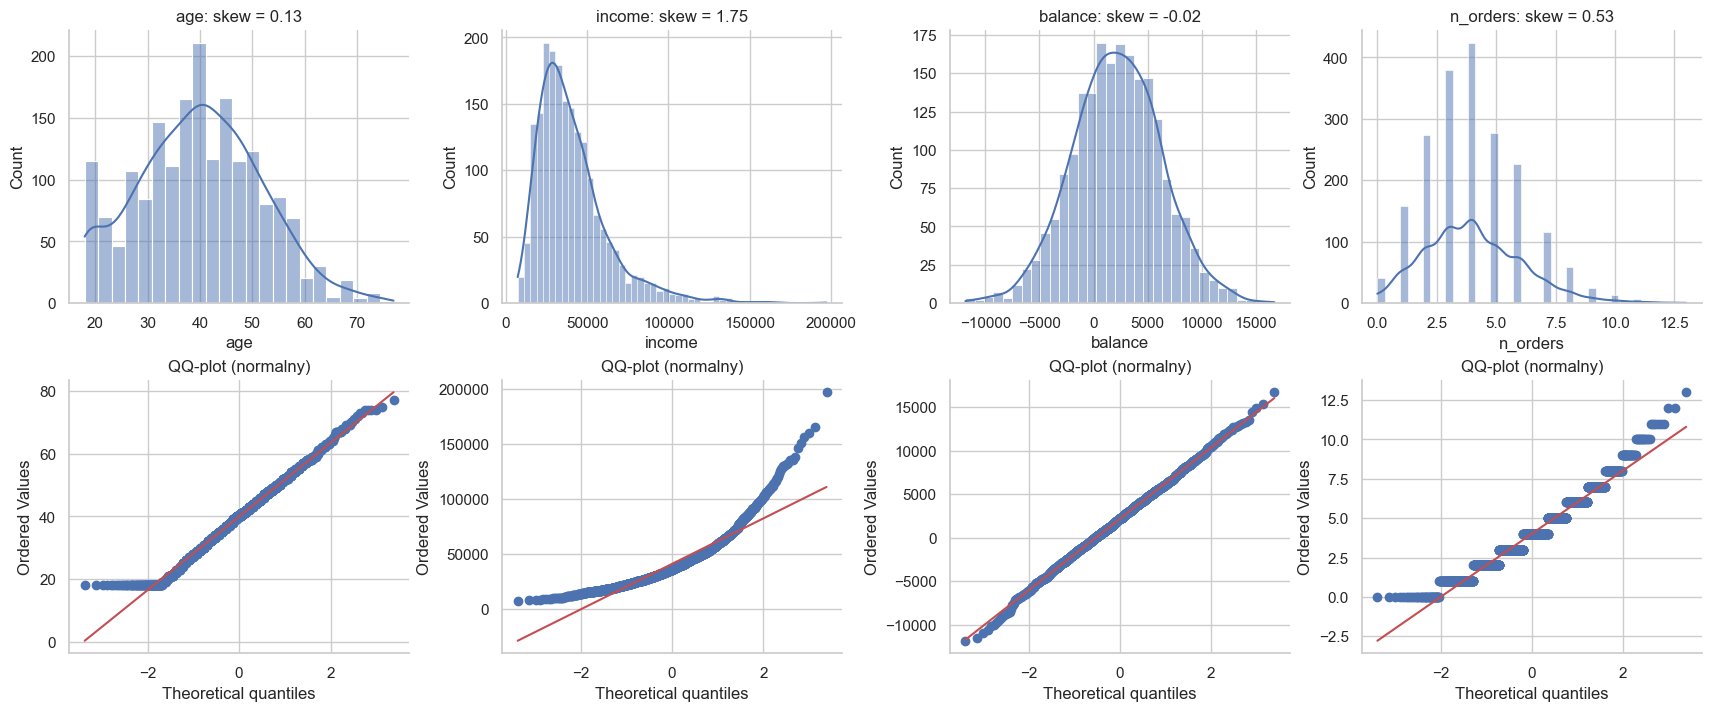

In [72]:
# wykresy: histogram + QQ-plot (odchylenie od linii = odstępstwo od normalności)
fig, axes = plt.subplots(2, 4, figsize=(17, 7), constrained_layout=True)
for j, c in enumerate(["age", "income", "balance", "n_orders"]):
    v = df[c].dropna()
    sns.histplot(v, kde=True, ax=axes[0, j]); axes[0, j].set_title(f"{c}: skew = {v.skew():.2f}")
    st.probplot(v, dist="norm", plot=axes[1, j]); axes[1, j].set_title("QQ-plot (normalny)")
plt.show()

### 5.2. Transformacje potęgowe i logarytmiczne

**Kiedy:** zmienne dodatnie z prawostronną skośnością (kwoty, dochody, czasy, liczności). Logarytm zamienia efekty **multiplikatywne** na **addytywne** (wzrost o 10% to stała różnica w skali log), stabilizuje wariancję i ogranicza wpływ outlierów.

| Transformacja | Wzór | Dane wejściowe | Uwagi |
|---|---|---|---|
| `log` | ln(x) | **x > 0** | Silna skośność |
| **`log1p`** | ln(1 + x) | x ≥ 0 | Dla zer i liczników; odwrotna: `expm1` |
| `sqrt` | √x | x ≥ 0 | Łagodniejsza niż log; liczności (Poisson) |
| `reciprocal` | 1/x | x ≠ 0 | Czasy → prędkości; odwraca kolejność |
| **Box-Cox** | (xᵏ − 1)/λ | x > 0 | λ dobierana z danych |
| **Yeo-Johnson** | uogólnienie Box-Cox | **dowolne x (także ≤ 0)** | Domyślny wybór, gdy są wartości ujemne |
| `arcsinh` / signed log | asinh(x) | dowolne x | Zachowuje znak; log-podobna dla dużych \|x\| |

#### Wersja podstawowa

In [73]:
# pandas
df["income_log"] = np.log1p(df["income"])
# Polars
df_pl = df_pl.with_columns(pl.col("income").log1p().alias("income_log"))
# scikit-learn: FunctionTransformer z funkcją odwrotną (inverse_transform) i nazwami kolumn
log_tf = FunctionTransformer(np.log1p, inverse_func=np.expm1, feature_names_out="one-to-one", check_inverse=False).set_output(transform="pandas")     # check_inverse=False: dane mają NaN
df[["income_log_sk"]] = log_tf.fit_transform(df[["income"]])

print("skośność przed:", round(df["income"].skew(), 2), "| po log1p:", round(df["income_log"].skew(), 2))
print(np.allclose(df["income_log"].dropna(), df["income_log_sk"].dropna()))

skośność przed: 1.75 | po log1p: 0.06
True


| Parametr `FunctionTransformer` | Opis |
|---|---|
| `func` ⬜ | Funkcja przekształcająca (`np.log1p`, `np.sqrt`, własna) |
| `inverse_func` ⬜ | Funkcja odwrotna (potrzebna do `inverse_transform`, np. przy `TransformedTargetRegressor`) |
| `validate` ⬜ | Walidacja wejścia (domyślnie `False`) |
| `feature_names_out` ⬜ | `"one-to-one"` zachowuje nazwy kolumn |
| `check_inverse` ⬜ | `True` (domyślnie) sprawdza, czy `inverse_func(func(x)) ≈ x` na próbce; przy danych z `NaN` ustaw `False` |
| `kw_args` ⬜ | Dodatkowe argumenty do `func` |

### 5.3. Box-Cox i Yeo-Johnson (`PowerTransformer`)

`PowerTransformer` **sam dobiera λ** (maksymalizując wiarygodność normalności) i domyślnie dodatkowo standaryzuje wynik (z-score). Interpretacja λ: λ ≈ 1 bez zmian, 0,5 ≈ pierwiastek, 0 ≈ logarytm, −1 ≈ odwrotność.

| Parametr `PowerTransformer` | Opis |
|---|---|
| `method` ⬜ | `"yeo-johnson"` (domyślnie; dowolne wartości) lub `"box-cox"` (**tylko x > 0**) |
| `standardize` ⬜ | `True` (domyślnie) = po transformacji z-score; `False` gdy standaryzujesz osobno |
| `copy` ⬜ | |

Atrybut: `lambdas_` (λ dla każdej kolumny). Obsługuje NaN (ignoruje przy fit).

In [74]:
# wersja podstawowa: kolumna dodatnia → Box-Cox lub Yeo-Johnson; kolumna z ujemnymi → Yeo-Johnson
pt = PowerTransformer(method="yeo-johnson", standardize=True).set_output(transform="pandas")
yj = pt.fit_transform(df[["income", "balance", "profit"]])
print("λ:", dict(zip(pt.feature_names_in_, pt.lambdas_.round(2))))
print("skośność po YJ:", yj.skew().round(2).to_dict(), "| przed:", df[["income", "balance", "profit"]].skew().round(2).to_dict())

# SciPy (pandas/Polars: wartości liczone na numpy i wstawione do kolumny)
vals = df["income"].dropna().to_numpy()
bc, lam = st.boxcox(vals)                                       # Box-Cox (tylko dodatnie), zwraca (dane, λ)
yj_vals, lam_yj = st.yeojohnson(vals)
print(f"Box-Cox λ = {lam:.3f}, Yeo-Johnson λ = {lam_yj:.3f}")
df_pl = df_pl.with_columns(pl.Series("income_bc", st.boxcox(df_pl["income"].fill_null(df_pl["income"].median()).to_numpy())[0]))     # Polars: Series z numpy

λ: {'income': np.float64(-0.04), 'balance': np.float64(1.0), 'profit': np.float64(1.01)}
skośność po YJ: {'income': -0.0, 'balance': 0.01, 'profit': 0.87} | przed: {'income': 1.75, 'balance': -0.02, 'profit': 0.22}
Box-Cox λ = -0.037, Yeo-Johnson λ = -0.037


### 5.4. Transformacja kwantylowa (`QuantileTransformer`)

**Co robi:** zamienia wartości na ich **rangi (percentyle)**, a następnie mapuje na rozkład jednostajny lub normalny. Neutralizuje outliery i dowolną skośność; kształt wynikowy jest ściśle zadany.
**Kiedy:** modele wrażliwe na rozkład (sieci, modele liniowe) przy bardzo nietypowych rozkładach; cechy wielomodalne. **Kosztem** są zniekształcone odległości i zerowa interpretowalność wartości, a przy małych próbach metoda przeucza się.

| Parametr `QuantileTransformer` | Opis |
|---|---|
| `n_quantiles` ⬜ | Liczba kwantyli (domyślnie 1000; nie więcej niż liczba obserwacji) |
| `output_distribution` ⬜ | `"uniform"` (domyślnie) lub `"normal"` |
| `subsample` ⬜ | Maks. liczba obserwacji do estymacji kwantyli (przyspiesza przy dużych danych) |
| `ignore_implicit_zeros` ⬜ | Dla macierzy rzadkich |
| `random_state`, `copy` ⬜ | |

In [75]:
qt = QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=0)
df["income_qn"] = qt.fit_transform(df[["income"]])

# pandas/Polars: ranga → percentyl → odwrotna dystrybuanta normalna (skala identyczna jak w sklearn z dokładnością do interpolacji)
pct = df["income"].rank(pct=True)
df["income_qn_pd"] = st.norm.ppf((pct * len(pct) - 0.5) / len(pct))
df_pl = df_pl.with_columns(((pl.col("income").rank() - 0.5) / pl.col("income").count()).alias("income_pct"))
print(df[["income_qn", "income_qn_pd"]].corr().iloc[0, 1].round(4))

0.9984


### 5.5. Porównanie transformacji (wykres)

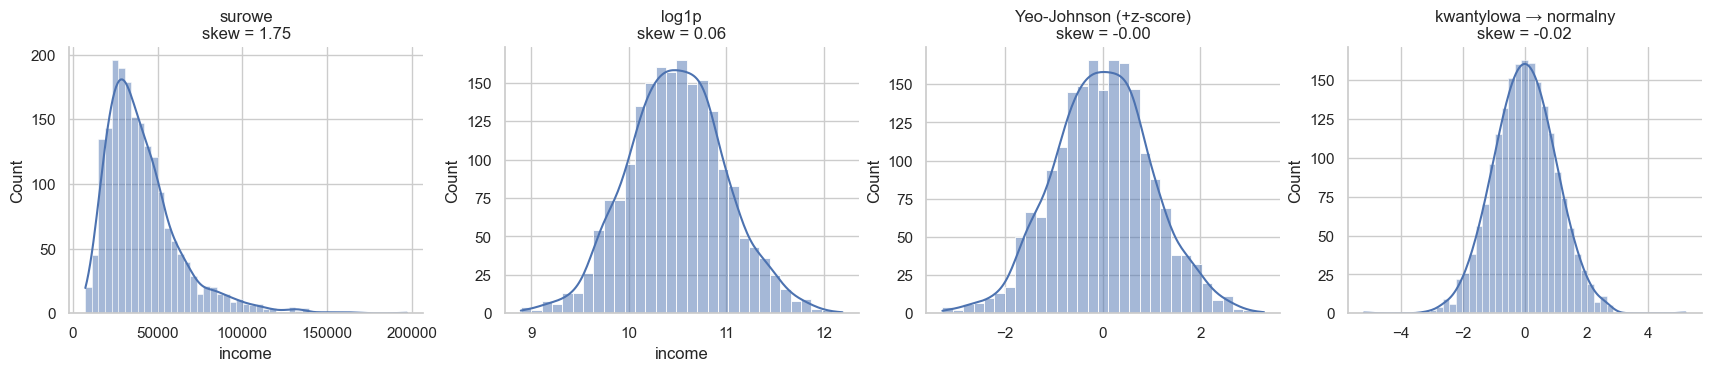

In [76]:
v = df[["income"]].dropna()
variants = {"surowe": v["income"],
            "log1p": np.log1p(v["income"]),
            "Yeo-Johnson (+z-score)": pd.Series(PowerTransformer().fit_transform(v).ravel(), index=v.index),
            "kwantylowa → normalny": pd.Series(QuantileTransformer(n_quantiles=200, output_distribution="normal").fit_transform(v).ravel(), index=v.index)}
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6), constrained_layout=True)
for ax, (name, s) in zip(axes, variants.items()):
    sns.histplot(s, kde=True, ax=ax, color="#4c72b0"); ax.set_title(f"{name}\nskew = {s.skew():.2f}")
plt.show()

### 5.6. Wartości odstające: wykrywanie i postępowanie

| Metoda wykrywania | Reguła | Kiedy |
|---|---|---|
| **IQR** | poza `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]` | Uniwersalna, odporna; domyślna |
| **z-score** | \|z\| > 3 | Dane zbliżone do normalnych (inaczej zawyża liczbę outlierów) |
| **Zmodyfikowany z-score (MAD)** | `0.6745·(x − mediana) / MAD`, próg 3,5 | Odporna wersja z-score |
| Percentyle | poniżej P1 / powyżej P99 | Gdy chcesz ograniczyć stały odsetek |

| Co to jest? | Postępowanie |
|---|---|
| **Błąd danych** (wiek 250 lat, ujemna cena) | Popraw lub usuń/ustaw jako brak, udokumentuj |
| **Prawdziwa, rzadka wartość** (duży klient) | Zostaw; w modelach liniowych/odległościowych użyj `RobustScaler`, log lub winsoryzacji; w drzewach zostaw bez zmian |
| **Odstające, ale ważne biznesowo** | Osobna analiza; flaga `is_outlier` jako cecha |
| Nie wiesz | Nie usuwaj „dla porządku": sprawdź źródło i porównaj wyniki z i bez |

In [77]:
s = df["income_outliers"]
# wykrywanie
q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
mask_iqr = (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)
mad = (s - s.median()).abs().median()
mask_mad = (0.6745 * (s - s.median()) / mad).abs() > 3.5
mask_z = ((s - s.mean()) / s.std()).abs() > 3
print({"IQR": int(mask_iqr.sum()), "MAD": int(mask_mad.sum()), "z>3": int(mask_z.sum())})

# winsoryzacja (przycięcie do percentyli): granice liczone na TRAIN i stosowane do wszystkich danych
lo, hi = s.quantile([.01, .99])
df["income_wins"] = s.clip(lower=lo, upper=hi)                                                    # pandas
df_pl = df_pl.with_columns(pl.col("income_outliers").clip(lower_bound=lo, upper_bound=hi).alias("income_wins"))          # Polars
from scipy.stats.mstats import winsorize
wins_sp = winsorize(s.dropna().to_numpy(), limits=(0.01, 0.01))                                    # SciPy (symetryczne 1%/1%)
print(df[["income_outliers", "income_wins"]].describe().round(0).T[["mean", "std", "max"]])

{'IQR': 114, 'MAD': 78, 'z>3': 17}
                    mean      std        max
income_outliers  44640.0  50015.0  1020986.0
income_wins      42125.0  24781.0   156757.0


> **Dobra praktyka:** nie usuwaj wierszy z outlierami z danych testowych/produkcyjnych. Model musi radzić sobie z takimi wartościami, więc zastosuj przycięcie (`clip`) z granicami z train, a nie kasowanie rekordów.

### 5.7. Dyskretyzacja (przedziały)

**Kiedy:** (a) w analizie: grupy wiekowe, koszyki cen, przedziały dochodu (czytelne dla odbiorcy); (b) w ML: modele liniowe z nieliniowym efektem cechy lub gdy cecha ma mało wiarygodną precyzję. **Koszt:** utrata informacji; drzewa i tak same szukają progów.

#### Wersja podstawowa

In [78]:
# pandas: przedziały wg własnych granic i według kwantyli
df["age_group"] = pd.cut(df["age"], bins=[17, 29, 44, 59, 80], labels=["18–29", "30–44", "45–59", "60+"])
df["income_q"] = pd.qcut(df["income"], q=4, labels=["Q1", "Q2", "Q3", "Q4"])

# Polars
df_pl = df_pl.with_columns(pl.col("age").cut([29, 44, 59], labels=["18–29", "30–44", "45–59", "60+"]).alias("age_group"),
                           pl.col("income").qcut(4, labels=["Q1", "Q2", "Q3", "Q4"]).alias("income_q"))
print(df["age_group"].value_counts().sort_index().to_dict())

{'18–29': 377, '30–44': 853, '45–59': 582, '60+': 88}


| Parametr `KBinsDiscretizer` | Opis |
|---|---|
| `n_bins` ⬜ | Liczba przedziałów (5 domyślnie), także lista na kolumnę |
| `encode` ⬜ | `"onehot"` (rzadka), `"onehot-dense"`, `"ordinal"` |
| `strategy` ⬜ | `"quantile"` (równe liczności; domyślnie), `"uniform"` (równa szerokość), `"kmeans"` (klastry 1D) |
| `quantile_method` (scikit-learn ≥ 1.7), `subsample`, `random_state` ⬜ | |

In [79]:
kb = KBinsDiscretizer(n_bins=5, encode="ordinal", strategy="quantile")      # quantile_method: scikit-learn ≥ 1.7 (w starszych usuń parametr)
df["income_bin"] = kb.fit_transform(df[["income"]].fillna(df["income"].median()))
print(kb.bin_edges_[0].round(0))

[  7286.  23978.  31964.  40062.  53051. 197311.]


## 6. Pozostałe typy liczbowe: binarne, liczniki, odsetki, kwoty z ujemnymi, skale porządkowe, cykliczne, współrzędne

Kolumna jest liczbą w typie danych, ale **nie zawsze jest „liczbą ciągłą"**. To najczęstsze źródło błędów: `StandardScaler` na kolumnie 0/1, numerze miesiąca lub identyfikatorze.

### 6.1. Binarne (bool, 0/1, tak/nie)

**Nie skaluj.** Wartości 0/1 są już „w skali" i mają interpretację („tak/nie"). Standaryzacja zamieniłaby je na dziwne liczby (np. −0,81 i 1,23) bez zysku. Wystarczy zapewnić **typ liczbowy 0/1**.

In [80]:
# pandas
df["is_returning_int"] = df["is_returning"].astype(int)
df["newsletter_flag"] = df["newsletter"].map({1: "tak", 0: "nie"})                       # (przykład tekstowej wersji)
back = df["newsletter_flag"].map({"tak": 1, "nie": 0})                                    # tekst → 0/1

# Polars
df_pl = df_pl.with_columns(pl.col("is_returning").cast(pl.Int8).alias("is_returning_int"))

# scikit-learn: kolumna tekstowa/kategoryczna o dwóch wartościach → jedna kolumna 0/1
ohe = OneHotEncoder(drop="if_binary", sparse_output=False)                                # if_binary: tylko jedna kolumna dla 2 kategorii
print(ohe.fit_transform(df[["newsletter_flag"]]).ravel()[:10], ohe.categories_)

[0. 0. 1. 1. 0. 1. 1. 0. 0. 1.] [array(['nie', 'tak'], dtype=object)]


### 6.2. Liczniki (0, 1, 2, …)

**Kiedy transformować:** liczniki mają skośny rozkład (Poissona) i wariancję rosnącą ze średnią. Dla modeli liniowych/odległościowych zwykle `log1p` lub `sqrt`; dla drzew bez zmian. W analizie **normalizuj przez ekspozycję** (zamówienia na rok aktywności, incydenty na 1000 klientów), bo suma bezwzględna wynika głównie z „czasu obserwacji" lub wielkości jednostki.

In [81]:
REF = pd.Timestamp("2026-01-01")                                           # data odniesienia (stała = powtarzalność wyników)

# pandas
df["years_active"] = (REF - df["signup_date"]).dt.days / 365.25
df["orders_per_year"] = df["n_orders"] / df["years_active"]               # wskaźnik względem ekspozycji
df["n_orders_log1p"] = np.log1p(df["n_orders"])

# Polars
df_pl = df_pl.with_columns(((pl.lit(REF) - pl.col("signup_date")).dt.total_days() / 365.25).alias("years_active"))
df_pl = df_pl.with_columns((pl.col("n_orders") / pl.col("years_active")).alias("orders_per_year"), pl.col("n_orders").log1p().alias("n_orders_log1p"))

print(df[["n_orders", "n_orders_log1p", "orders_per_year"]].skew().round(2).to_dict())

{'n_orders': 0.53, 'n_orders_log1p': -0.83, 'orders_per_year': 2.28}


### 6.3. Odsetki i proporcje w [0, 1] (`discount_rate`, `conversion_rate`)

| Sytuacja | Postępowanie |
|---|---|
| Zapis w procentach (0–100) | Przelicz na ułamek 0–1 (jedna jednostka w całej tabeli) |
| Model drzewiasty / do raportu | Zostaw bez zmian |
| Model liniowy, gdy wartości przy 0 lub 1 są „ściśnięte" | **logit** `ln(p/(1−p))` lub `arcsin(√p)` (rozciąga końce przedziału) |
| Wartości dokładnie 0 lub 1 | Przytnij do `[ε, 1−ε]` przed logitem (inaczej ±∞) |
| Z-score | W modelach wrażliwych na skalę **tak** (ułamek ma σ ≪ 1, więc bez skalowania miałby znikomy wpływ w odległościach i regularyzacji); w drzewach i raportach nie |

In [82]:
eps = 1e-4
p = df["conversion_rate"].clip(eps, 1 - eps)

df["conv_logit"] = np.log(p / (1 - p))                                    # pandas/NumPy
df["conv_asin"] = np.arcsin(np.sqrt(df["conversion_rate"]))
df_pl = df_pl.with_columns(((pl.col("conversion_rate").clip(eps, 1 - eps)) / (1 - pl.col("conversion_rate").clip(eps, 1 - eps))).log().alias("conv_logit"))

from scipy.special import logit
logit_tf = FunctionTransformer(lambda a: logit(np.clip(a, eps, 1 - eps)), feature_names_out="one-to-one")        # w pipeline (scikit-learn)
print("skośność:", round(df["conversion_rate"].skew(), 2), "→ logit:", round(df["conv_logit"].skew(), 2))

skośność: 1.12 → logit: -0.87


### 6.4. Kwoty z wartościami ujemnymi (`balance`, `profit`)

`log` i Box-Cox wymagają wartości dodatnich. Opcje:

| Metoda | Kiedy |
|---|---|
| **Yeo-Johnson** (`PowerTransformer`) | Domyślny wybór: działa dla dowolnych liczb |
| **`arcsinh(x / s)`** | Zachowuje znak i „loguje" duże wartości; `s` = typowa skala (np. mediana \|x\|) |
| **Signed log** `sign(x)·log1p(\|x\|)` | Prosta, interpretowalna wersja dla znaków |
| **`RobustScaler`** | Gdy chcesz tylko ograniczyć wpływ rozrzutu, bez zmiany kształtu |
| Rozdzielenie: znak + log(\|x\|) | Gdy znak ma osobne znaczenie (zysk/strata) |

In [83]:
s = df["profit"]
scale = s.abs().median()

df["profit_asinh"] = np.arcsinh(s / scale)
df["profit_slog"] = np.sign(s) * np.log1p(s.abs())
df_pl = df_pl.with_columns((pl.col("profit") / scale).arcsinh().alias("profit_asinh"),
                           (pl.col("profit").sign() * pl.col("profit").abs().log1p()).alias("profit_slog"))

print(pd.DataFrame({"surowe": s, "asinh": df["profit_asinh"], "signed log": df["profit_slog"],
                    "Yeo-Johnson": PowerTransformer().fit_transform(df[["profit"]]).ravel()}).agg(["skew", "kurt"]).round(2))

      surowe  asinh  signed log  Yeo-Johnson
skew    0.22  -0.42       -0.63         0.87
kurt   16.20  -0.17       -1.43        18.42


### 6.5. Skale porządkowe (`satisfaction` 1–5, `segment`)

Skala porządkowa ma **kolejność, ale niekoniecznie równe odstępy** (różnica 1→2 nie musi być równa 4→5).

| Przypadek | Postępowanie |
|---|---|
| Ocena 1–5 w drzewach | Zostaw jako liczbę (drzewa używają tylko kolejności) |
| Ocena 1–5 w modelu liniowym | Zostaw jako liczbę (zakładasz liniowy efekt), albo one-hot/`OrdinalEncoder` + testy, jeśli efekt jest nieliniowy |
| Kategoria uporządkowana tekstowa (`Basic < Standard < Premium`) | `OrdinalEncoder` z **jawną kolejnością** (nie alfabetyczną!) |
| Z-score | Tylko jeśli łączysz skalę z innymi cechami w modelu wrażliwym na skalę (sekcja 2) |
| W analizie | Mediana i rozkład odpowiedzi (% w każdej kategorii) zamiast średniej, gdy odstępy nie są równe |

#### Wersja podstawowa

In [84]:
# pandas: typ kategoryczny uporządkowany → kody liczbowe
df["segment_code"] = df["segment"].cat.codes                                   # Basic=0, Standard=1, Premium=2 (braki = -1!)

# Polars: Enum (ustalona kolejność) → fizyczne kody
df_pl = df_pl.with_columns(pl.col("segment").cast(pl.Enum(["Basic", "Standard", "Premium"])).to_physical().alias("segment_code"))

# scikit-learn
oe = OrdinalEncoder(categories=[["Basic", "Standard", "Premium"]], handle_unknown="use_encoded_value", unknown_value=-1, encoded_missing_value=np.nan)
df["segment_code_sk"] = oe.fit_transform(df[["segment"]].astype(str))
print(df["segment_code"].value_counts().sort_index().to_dict())

{0: 879, 1: 820, 2: 301}


| Parametr `OrdinalEncoder` | Opis |
|---|---|
| `categories` ⬜ | `"auto"` (**kolejność alfabetyczna**, zwykle zła!) lub lista list z jawną kolejnością |
| `handle_unknown` ⬜ | `"error"` (domyślnie) lub `"use_encoded_value"` (+ `unknown_value`) |
| `unknown_value` ⬜ | Kod dla nieznanych kategorii (np. `-1` lub `np.nan`) |
| `encoded_missing_value` ⬜ | Kod dla braków (domyślnie `NaN`) |
| `min_frequency`, `max_categories` ⬜ | Łączenie rzadkich kategorii |
| `dtype` ⬜ | Typ wyniku |

### 6.6. Współrzędne geograficzne (`lat`, `lon`)

**Nie standaryzuj `lat` i `lon` osobno** dla modeli odległościowych. Stopień szerokości to ok. 111 km, a stopień długości na 52°N ok. 68 km, więc osobne z-score zniekształcają geometrię (przy tym różne σ cech przeskalowałyby je różnie). Opcje:

| Metoda | Kiedy |
|---|---|
| **Układ rzutowany w metrach** (Polska: EPSG:2180) | Odległości euklidesowe, KNN, klastrowanie, bufory; zgodne z GeoPandas |
| **Odległość haversine** (`BallTree(metric="haversine")`) | Odległości po sferze w skali kraju/świata |
| **Wektor jednostkowy 3D** (x, y, z na sferze) | Gdy potrzebujesz euklidesowych cech dla modelu |
| Surowe lat/lon | Modele drzewiaste (dzielą oś po osi) |
| Cechy pochodne | Odległość do centrum miasta/sklepu, klaster/region, identyfikator siatki (H3) |

In [85]:
from pyproj import Transformer
from sklearn.neighbors import BallTree

# a) układ metryczny EPSG:2180 (x, y w metrach); dopiero potem ewentualnie skalowanie wspólną skalą (nie osobno!)
tr = Transformer.from_crs(4326, 2180, always_xy=True)
df["x_m"], df["y_m"] = tr.transform(df["lon"].to_numpy(), df["lat"].to_numpy())

# b) haversine: odległość do najbliższych sąsiadów w km
rad = np.radians(df[["lat", "lon"]].to_numpy())
tree = BallTree(rad, metric="haversine")
dist, ind = tree.query(rad[:3], k=4)
print((dist * 6371.0088).round(1))                                          # km (pierwsza kolumna = 0: punkt sam do siebie)

# c) wektor jednostkowy 3D
df["geo_x"] = np.cos(rad[:, 0]) * np.cos(rad[:, 1]); df["geo_y"] = np.cos(rad[:, 0]) * np.sin(rad[:, 1]); df["geo_z"] = np.sin(rad[:, 0])
print(df[["lat", "lon", "x_m", "y_m"]].head(2).round(1))

[[ 0.   8.1 13.7 13.7]
 [ 0.   9.6 10.5 11.1]
 [ 0.   8.3 15.6 17.7]]
    lat   lon       x_m       y_m
0  52.8  22.9  764500.3  553916.7
1  50.8  16.0  288099.8  326044.6


### 6.7. Cechy cykliczne (`hour`, `weekday`, `order_month`)

Godzina 23 jest **blisko** 0, ale jako liczba różnica wynosi 23. Z-score tego nie naprawia. Kodowanie `sin/cos` na okręgu zachowuje bliskość.

| Cecha | Okres |
|---|---|
| `hour` (0–23) | 24 |
| `weekday` (0–6) | 7 |
| `order_month` (1–12) | 12 (przesuń: `month − 1`) |
| dzień roku | 365,25 |

In [86]:
# pandas / NumPy
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
df["month_sin"] = np.sin(2 * np.pi * (df["order_month"] - 1) / 12)
df["month_cos"] = np.cos(2 * np.pi * (df["order_month"] - 1) / 12)

# Polars
df_pl = df_pl.with_columns((pl.col("hour") * 2 * np.pi / 24).sin().alias("hour_sin"), (pl.col("hour") * 2 * np.pi / 24).cos().alias("hour_cos"))

# scikit-learn: gładsze, elastyczniejsze kodowanie (periodic splines), dobre do modeli liniowych
spl = SplineTransformer(degree=3, n_knots=13, knots=np.linspace(0, 24, 13).reshape(-1, 1), extrapolation="periodic", include_bias=False)
hour_spl = spl.fit_transform(df[["hour"]])
print("kolumn splajnu:", hour_spl.shape[1])

# kontrola: odległość 23:00 ↔ 00:00 przed i po
pts = pd.DataFrame({"hour": [23, 0, 12]})
pts["sin"], pts["cos"] = np.sin(2 * np.pi * pts["hour"] / 24), np.cos(2 * np.pi * pts["hour"] / 24)
d = lambda a, b: float(np.hypot(pts.loc[a, "sin"] - pts.loc[b, "sin"], pts.loc[a, "cos"] - pts.loc[b, "cos"]))
print(f"23 vs 0: surowo = 23, po sin/cos = {d(0, 1):.2f} | 0 vs 12: surowo = 12, po sin/cos = {d(1, 2):.2f}")

kolumn splajnu: 11
23 vs 0: surowo = 23, po sin/cos = 0.26 | 0 vs 12: surowo = 12, po sin/cos = 2.00


> Dla modeli **drzewiastych** surowa godzina zwykle wystarcza (drzewo znajdzie podział „21–5"), ale `sin/cos` nie szkodzi. Dla regresji liniowej, KNN i sieci kodowanie cykliczne jest istotne.

### 6.8. Identyfikatory, kolumny stałe i prawie stałe

| Typ | Rozpoznanie | Co robić |
|---|---|---|
| **Identyfikator** (`customer_id`) | Unikalny w każdym wierszu; nazwa `*_id` | **Usuń z cech** (model uczy się „zapamiętywać", nie generalizować) |
| **Stała** (`country`) | 1 unikalna wartość | Usuń |
| **Prawie stała** (`tier_code`: 99,5% „A") | Wariancja ≈ 0 / dominująca kategoria > 99% | Usuń lub zostaw jako flagę rzadkiego zdarzenia (jeśli ma sens biznesowy) |

In [87]:
# pandas
nun = df.nunique()
print(nun[["customer_id", "country", "tier_code"]].to_dict())
dominant = df[["country", "tier_code", "region"]].apply(lambda c: c.value_counts(normalize=True, dropna=False).iloc[0])
print(dominant.round(3).to_dict())

# Polars
print(df_pl.select(pl.col("customer_id", "country", "tier_code").n_unique()).row(0, named=True))

# scikit-learn: VarianceThreshold dla kolumn liczbowych (0.0 = tylko stałe)
vt = VarianceThreshold(threshold=0.0).fit(df[["age", "n_orders", "newsletter"]].fillna(0))
print("zachowane:", vt.get_feature_names_out())

{'customer_id': 2000, 'country': 1, 'tier_code': 2}
{'country': 1.0, 'tier_code': 0.994, 'region': 0.232}
{'customer_id': 2000, 'country': 1, 'tier_code': 2}
zachowane: ['age' 'n_orders' 'newsletter']


## 7. Kategorie, daty, tekst, liczby zapisane jako tekst i braki danych

### 7.1. Kategorie nominalne o niskiej kardynalności (`region`, `channel`)

**Kodowanie one-hot:** jedna kolumna 0/1 na kategorię. Nie skaluj wyników.

#### Wersja podstawowa

In [88]:
# pandas
pd.get_dummies(df[["region", "channel"]], dtype=int).head(3)
# Polars
df_pl.select(["region", "channel"]).to_dummies().head(3)
# scikit-learn
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
Xo = ohe.fit_transform(df[["region", "channel"]].fillna("brak"))
print(ohe.get_feature_names_out())

['region_Centrum' 'region_Południe' 'region_Północ' 'region_Wschód'
 'region_Zachód' 'region_brak' 'channel_Online' 'channel_Sklep'
 'channel_Telefon']


| Parametr `OneHotEncoder` | Opis |
|---|---|
| `categories` ⬜ | `"auto"` lub jawne listy kategorii |
| `drop` ⬜ | `None`, `"first"` (usuwa kolumnę bazową: modele liniowe bez regularyzacji, unika współliniowości), `"if_binary"` |
| `sparse_output` ⬜ | `True` (domyślnie, macierz rzadka) / `False` (gęsta) |
| `handle_unknown` ⬜ | `"error"` (domyślnie), **`"ignore"`** (nieznana kategoria → same zera), `"infrequent_if_exist"` |
| `min_frequency` ⬜ | Kategorie rzadsze niż próg (liczba lub ułamek) łączone w „infrequent" |
| `max_categories` ⬜ | Maks. liczba kolumn na cechę (reszta jako „infrequent") |
| `feature_name_combiner` ⬜ | Sposób nazywania kolumn |
| `dtype` ⬜ | |

| Parametr `pd.get_dummies` / `DataFrame.to_dummies` | Opis |
|---|---|
| `columns` ⬜ | Które kolumny (domyślnie wszystkie tekstowe/kategoryczne) |
| `drop_first` ⬜ | Usuń pierwszą kategorię |
| `dummy_na` ⬜ | (pandas) Osobna kolumna dla braków |
| `dtype` ⬜ | (pandas) `int` zamiast `bool` |
| `separator` ⬜ | (Polars) Separator w nazwach kolumn |

> **`get_dummies` w produkcji jest ryzykowne:** nie „pamięta" kategorii z treningu, więc zestaw kolumn może się różnić między train a nowymi danymi. W pipeline zawsze używaj `OneHotEncoder(handle_unknown="ignore")`.
> **Modele drzewiaste:** one-hot nie jest konieczny. `HistGradientBoostingClassifier(categorical_features="from_dtype")` (kolumny typu `category`) oraz LightGBM/CatBoost obsługują kategorie natywnie, często lepiej niż one-hot.

### 7.2. Kategorie o wysokiej kardynalności (`city`: 150 wartości)

One-hot dałoby 150 kolumn, w większości rzadkich. Opcje:

| Metoda | Zasada | Uwagi |
|---|---|---|
| **Łączenie rzadkich** | Kategorie poniżej progu → „inne" | `OneHotEncoder(min_frequency=…, max_categories=…)`; proste i bezpieczne |
| **Kodowanie częstością** | Kategoria → jej udział w zbiorze | Bez użycia celu, więc bez wycieku; liczone **na train** |
| **Target encoding** | Kategoria → (wygładzona) średnia celu | Potężne, ale **wymaga walidacji krzyżowej** (sekcja 3.1); `TargetEncoder` |
| **Hashing** | Funkcja skrótu → stała liczba kolumn | `FeatureHasher`; brak interpretowalności, kolizje |
| **Hierarchia** | Miasto → powiat → region | Najlepsze merytorycznie, jeśli masz słownik |
| **Natywne kategorie** | Boosting z `categorical_features` | Drzewa |

In [89]:
X_tr, X_te, y_tr, y_te = train_test_split(df[["city"]], df["churn"], test_size=0.25, random_state=42, stratify=df["churn"])

# a) częstość: statystyki z TRAIN, nieznane miasta → 0
freq = X_tr["city"].value_counts(normalize=True)                                           # pandas
X_te_freq = X_te["city"].map(freq).fillna(0)

tr_pl = pl.from_pandas(X_tr.reset_index(drop=True)); te_pl = pl.from_pandas(X_te.reset_index(drop=True))               # Polars
freq_pl = tr_pl.group_by("city").agg((pl.len() / tr_pl.height).alias("city_freq"))
te_freq_pl = te_pl.join(freq_pl, on="city", how="left").with_columns(pl.col("city_freq").fill_null(0))

# b) rzadkie kategorie łączone w „infrequent"
ohe = OneHotEncoder(min_frequency=0.01, handle_unknown="infrequent_if_exist", sparse_output=False).fit(X_tr)
print("kolumn po połączeniu rzadkich:", len(ohe.get_feature_names_out()), "(zamiast", X_tr["city"].nunique(), ")")

# c) TargetEncoder (cv wewnątrz fit_transform treningu; transform testu używa pełnego modelu)
te = TargetEncoder(target_type="binary", smooth="auto", cv=5, random_state=0)
X_tr_te = te.fit_transform(X_tr, y_tr)
X_te_te = te.transform(X_te)
print(pd.DataFrame(X_te_te, columns=["city_te"]).describe().round(3).T[["mean", "std"]])

# d) hashing: stała liczba kolumn niezależnie od liczby kategorii
from sklearn.feature_extraction import FeatureHasher
fh = FeatureHasher(n_features=16, input_type="string")
Xh = fh.transform(X_tr["city"].astype(str).to_frame().to_numpy()).toarray()
print(Xh.shape)

kolumn po połączeniu rzadkich: 12 (zamiast 150 )
          mean    std
city_te  0.466  0.168
(1500, 16)


C:\Users\pkawk\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


| Parametr `TargetEncoder` | Opis |
|---|---|
| `categories` ⬜ | `"auto"` lub jawne |
| `target_type` ⬜ | `"auto"`, `"binary"`, `"continuous"`, `"multiclass"` |
| `smooth` ⬜ | `"auto"` (empiryczny Bayes) lub liczba: siła „ściągania" średnich małych kategorii do średniej globalnej |
| `cv` ⬜ | Liczba foldów przy kodowaniu treningu (zapobiega wyciekowi) |
| `shuffle`, `random_state` ⬜ | |

### 7.3. Daty i czas (`signup_date`, `last_login`)

**Surowy znacznik czasu (timestamp) nie nadaje się do skalowania:** jest liczbą rosnącą w czasie, więc model „wyjdzie poza zakres" w przyszłości. Zamiast tego twórz **cechy z dat**:

| Cecha | Przykład | Po co |
|---|---|---|
| Składowe | rok, kwartał, miesiąc, dzień tygodnia, godzina | Sezonowość (cyklicznie → 6.7) |
| **Wiek / czas trwania** | dni od rejestracji do daty odniesienia | Staż, aktualność |
| Różnice dat | `last_login − signup_date` | Aktywność |
| Flagi | weekend, święto, koniec miesiąca | Efekty kalendarzowe |
| Czas do zdarzenia | dni do końca umowy | Ryzyko |

> Używaj **stałej daty odniesienia** (np. data pobrania danych), a nie `today()`, żeby wyniki były powtarzalne. Przy walidacji danych szeregów czasowych dziel **chronologicznie** (`TimeSeriesSplit`), nie losowo.

In [90]:
# pandas
df["signup_year"] = df["signup_date"].dt.year
df["signup_dow"] = df["signup_date"].dt.dayofweek                                            # 0 = poniedziałek
df["is_weekend"] = (df["signup_dow"] >= 5).astype(int)
df["tenure_days"] = (REF - df["signup_date"]).dt.days
df["days_to_last_login"] = (df["last_login"] - df["signup_date"]).dt.total_seconds() / 86400

# Polars
df_pl = df_pl.with_columns(pl.col("signup_date").dt.year().alias("signup_year"),
                           pl.col("signup_date").dt.weekday().alias("signup_dow_pl"),                      # w Polars 1 = poniedziałek (inna numeracja niż pandas!)
                           (pl.lit(REF) - pl.col("signup_date")).dt.total_days().alias("tenure_days"))
print(df[["signup_year", "signup_dow", "tenure_days", "days_to_last_login"]].describe().round(1).T[["mean", "min", "max"]])

                      mean     min     max
signup_year         2022.0  2020.0  2024.0
signup_dow             3.1     0.0     6.0
tenure_days         1280.2   369.0  2190.0
days_to_last_login  4301.5     1.2  8758.4


### 7.4. Tekst: standaryzacja zapisu (`name_raw`, `email`)

Ten sam obiekt zapisany na różne sposoby (`" jan  KOWALSKI"`, `"Jan Kowalski"`) tworzy sztucznie wiele kategorii i psuje łączenia (`join`), grupowania i deduplikację.

**Standardowa kolejność czyszczenia:** (1) usuń spacje z brzegów, (2) zwiń wielokrotne spacje, (3) ujednolić wielkość liter, (4) opcjonalnie normalizuj Unicode/znaki diakrytyczne, (5) zamień warianty na wzorzec (słownik).

| Krok | pandas (`.str`) | Polars (`.str`) |
|---|---|---|
| Spacje z brzegów | `.str.strip()` | `.str.strip_chars()` |
| Zwiń spacje | `.str.replace(r"\s+", " ", regex=True)` | `.str.replace_all(r"\s+", " ")` |
| Wielkość liter | `.str.lower()`, `.str.title()` | `.str.to_lowercase()`, `.str.to_titlecase()` |
| Usuń znaki specjalne | `.str.replace(r"[^\w\s]", "", regex=True)` | `.str.replace_all(r"[^\w\s]", "")` |
| Normalizacja Unicode | `.str.normalize("NFKD")` | `.str.normalize("NFKD")` |

In [91]:
# pandas
name = df["name_raw"].str.strip().str.replace(r"\s+", " ", regex=True).str.title()
email = df["email"].str.strip().str.lower()
print("unikalnych imion i nazwisk: przed =", df["name_raw"].nunique(), "| po czyszczeniu =", name.nunique())
print("unikalnych e-maili po zmianie wielkości liter:", df["email"].nunique(), "→", email.nunique())     # e-maile są unikalne, więc bez zmian: ważne dla deduplikacji

# Polars
df_pl = df_pl.with_columns(pl.col("name_raw").str.strip_chars().str.replace_all(r"\s+", " ").str.to_titlecase().alias("name_clean"),
                           pl.col("email").str.strip_chars().str.to_lowercase().alias("email_clean"))
print(df_pl["name_clean"].n_unique())

# polskie znaki: normalizacja NFKD NIE rozkłada „ł/Ł" (to osobna litera), więc dodaj tłumaczenie
tab = str.maketrans({"ł": "l", "Ł": "L"})
ascii_pd = (pd.Series(["Łódź", "Wójcik", "wiśniewska"]).str.translate(tab).str.normalize("NFKD").str.encode("ascii", "ignore").str.decode("ascii"))
ascii_pl = (pl.Series(["Łódź", "Wójcik", "wiśniewska"]).str.replace_all("ł", "l").str.replace_all("Ł", "L").str.normalize("NFKD").str.replace_all(r"\p{M}", ""))
print(ascii_pd.tolist(), ascii_pl.to_list())

# warianty zapisu → wzorzec (słownik); przy wielu wariantach użyj dopasowania rozmytego (np. rapidfuzz)
variants = pd.Series(["Warszawa", "warszawa", "WAWA", "W-wa", "Kraków", "Krakow", "krk"])
mapping = {"warszawa": "Warszawa", "wawa": "Warszawa", "w-wa": "Warszawa", "kraków": "Kraków", "krakow": "Kraków", "krk": "Kraków"}
print(variants.str.strip().str.lower().map(mapping).tolist())

unikalnych imion i nazwisk: przed = 72 | po czyszczeniu = 36
unikalnych e-maili po zmianie wielkości liter: 2000 → 2000
36
['Lodz', 'Wojcik', 'wisniewska'] ['Lodz', 'Wojcik', 'wisniewska']
['Warszawa', 'Warszawa', 'Warszawa', 'Warszawa', 'Kraków', 'Kraków', 'Kraków']


**Tekst swobodny (`comment`):** to nie jest kategoria. Do modelu zamieniasz go na cechy liczbowe: `TfidfVectorizer` (`lowercase`, `strip_accents`, `ngram_range`, `min_df`, `max_features`, `stop_words`), długość tekstu, liczba słów, osadzenia (embeddings). `TfidfVectorizer` domyślnie normalizuje wiersze (`norm="l2"`), więc **nie skaluje się go dodatkowo**.

In [92]:
from sklearn.feature_extraction.text import TfidfVectorizer
tf = TfidfVectorizer(lowercase=True, strip_accents="unicode", ngram_range=(1, 2), min_df=20, max_features=50)
Xt = tf.fit_transform(df["comment"])
df["comment_len"] = df["comment"].str.len()                                  # cecha prosta: długość komentarza
print(Xt.shape, tf.get_feature_names_out()[:5])

(2000, 50) ['dobrze' 'dostawa' 'dostawa produkt' 'dostawa swietny' 'dostawa zwrot']


### 7.5. Liczby i daty zapisane jako tekst (`revenue_text`, `pct_text`, `signup_text`)

Typowe dla plików z Excela i CSV: `"1 234,50 zł"`, `"12,5%"`, `"03.07.2022"`. Zanim cokolwiek skalujesz, **przekonwertuj na właściwy typ**. Zasada: usuń wszystko poza cyframi, znakiem i przecinkiem dziesiętnym, zamień `,` na `.`, rzutuj.

In [93]:
# pandas
df["revenue_num"] = (df["revenue_text"].str.replace(r"[^\d,\-]", "", regex=True).str.replace(",", ".", regex=False).astype(float))
df["pct_num"] = df["pct_text"].str.replace("%", "", regex=False).str.replace(",", ".", regex=False).astype(float) / 100
df["signup_dt"] = pd.to_datetime(df["signup_text"], format="%d.%m.%Y")

# Polars
df_pl = df_pl.with_columns(
    pl.col("revenue_text").str.replace_all(r"[^\d,\-]", "").str.replace(",", ".", literal=True).cast(pl.Float64).alias("revenue_num"),
    (pl.col("pct_text").str.replace("%", "", literal=True).str.replace(",", ".", literal=True).cast(pl.Float64) / 100).alias("pct_num"),
    pl.col("signup_text").str.to_date("%d.%m.%Y").alias("signup_dt"))

print(np.allclose(df["revenue_num"], df["revenue"]), np.allclose(df["pct_num"], df["discount_rate"], atol=0.0006), (df["signup_dt"] == df["signup_date"]).all())

True True True


> **Przy wczytywaniu plików zrób to od razu:** `pd.read_csv(path, decimal=",", thousands=" ", parse_dates=["data"], dayfirst=True)`; w Polars `pl.read_csv(path, decimal_comma=True)`. `pd.to_numeric(s, errors="coerce")` zamienia nieprzekonwertowalne wartości na `NaN`, a ich liczbę warto sprawdzić (`s.isna().sum()`) przed dalszą pracą.

### 7.6. Braki danych

Braki trzeba obsłużyć **przed** skalowaniem większości modeli (poza drzewami z natywną obsługą `NaN`, jak `HistGradientBoosting`, XGBoost, LightGBM).

| Metoda | Kiedy | Uwagi |
|---|---|---|
| Usunięcie wierszy | Mało braków (< 1–2%), losowych | Zmniejsza próbę; ryzyko obciążenia |
| **Mediana** (liczby) / **moda** (kategorie) | Prosty, odporny punkt wyjścia | Zmniejsza wariancję |
| Średnia | Rozkład symetryczny | Wrażliwa na outliery |
| Stała / „brak" | Kategorie; brak = informacja | Dla kategorii często najlepsze |
| **Wskaźnik braku** (`add_indicator=True`) | Gdy sam fakt braku jest informacją (MNAR) | Dodaje kolumnę 0/1 |
| `KNNImputer` | Gdy cechy są powiązane | Wymaga wcześniej skali; wolniejszy |
| `IterativeImputer` (MICE) | Złożone zależności | Eksperymentalny w scikit-learn |
| Forward fill / interpolacja | Szeregi czasowe | Tylko wzdłuż czasu |

In [94]:
# pandas
age_filled = df["age"].fillna(df["age"].median())
region_filled = df["region"].fillna("brak")
share = df.isna().mean().sort_values(ascending=False).head(5).round(3)               # udział braków
print(share.to_dict())

# Polars (pl.from_pandas zamienia NaN na null)
df_pl = df_pl.with_columns(pl.col("age").fill_null(pl.col("age").median()).alias("age_filled"),
                           pl.col("region").fill_null("brak").alias("region_filled"))
print(df_pl.null_count().select(["age", "income", "satisfaction", "region"]).row(0, named=True))

# scikit-learn: wyuczone na train, z kolumną wskaźnikową
imp = SimpleImputer(strategy="median", add_indicator=True)
Xi = imp.fit_transform(df[["age", "income", "satisfaction"]])
print(Xi.shape, imp.get_feature_names_out())

{'satisfaction': 0.08, 'age': 0.05, 'age_mm_sk': 0.05, 'age_z_pd': 0.05, 'age_z_sk': 0.05}
{'age': 100, 'income': 60, 'satisfaction': 160, 'region': 40}
(2000, 6) ['age' 'income' 'satisfaction' 'missingindicator_age'
 'missingindicator_income' 'missingindicator_satisfaction']


| Parametr `SimpleImputer` | Opis |
|---|---|
| `strategy` ⬜ | `"mean"`, `"median"`, `"most_frequent"`, `"constant"` |
| `fill_value` ⬜ | Wartość dla `strategy="constant"` |
| `missing_values` ⬜ | Co uznać za brak (`np.nan`, `None`, `-999`) |
| `add_indicator` ⬜ | Dodaje kolumny `missingindicator_*` |
| `keep_empty_features` ⬜ | Zachowuje kolumny w całości puste |

**Kolejność w pipeline:** czyszczenie/parsowanie → **imputacja** → transformacja rozkładu → **skalowanie** → model. Imputacja przed skalowaniem, bo skaler liczy statystyki z kompletnych danych (choć `StandardScaler` toleruje `NaN`, model go nie zniesie).

## 8. Standaryzacja w codziennej analizie (bez ML)

W raportach i analizach celem jest **porównywalność i czytelność**, a nie spełnienie założeń algorytmu. Odbiorca rozumie „+12% r/r" lub „indeks 112", a nie „z = 0,43".

| Cel analizy | Standaryzacja | Przykład |
|---|---|---|
| Porównać jednostki różnej wielkości | **Wskaźnik na jednostkę** (na mieszkańca, klienta, m², rok) | Przychód na sklep, zamówienia na klienta-rok |
| Porównać w obrębie grupy | **z-score w grupie**, percentyl w grupie, odchylenie od mediany grupy | Handlowiec względem regionu |
| Pokazać zmianę w czasie | **Indeks (baza = 100)**, zmiana % r/r | Sprzedaż vs styczeń 2023 = 100 |
| Pokazać strukturę | **Udział w całości** (% of total) | Udział kanałów w przychodzie |
| Uporządkować, wybrać „top" | **Ranga, percentyl, decyl** | Top 10% klientów |
| Porównać różne miary | z-score lub min-max do wspólnej skali (indeks syntetyczny) | Wynik łączący sprzedaż, NPS i terminowość |
| Wykryć anomalie | z-score (okno kroczące), IQR | Dzienny skok sprzedaży |
| Zestawić z celem/benchmarkiem | Realizacja planu (%), różnica do mediany rynku | |

### 8.1. z-score w grupach

In [95]:
# pandas: statystyki grupowe przez transform (wektorowo, bez lambd)
g = df.groupby("region")["income"]
df["income_z_region"] = (df["income"] - g.transform("mean")) / g.transform("std")

# Polars: funkcje okienne over()
df_pl = df_pl.with_columns(((pl.col("income") - pl.col("income").mean().over("region")) / pl.col("income").std().over("region")).alias("income_z_region"))

print(df.groupby("region")["income_z_region"].agg(["mean", "std"]).round(2))        # w każdym regionie ≈ (0, 1)
print(df.nlargest(3, "income_z_region")[["customer_id", "region", "income", "income_z_region"]])

          mean  std
region             
Centrum   -0.0  1.0
Południe  -0.0  1.0
Północ    -0.0  1.0
Wschód     0.0  1.0
Zachód     0.0  1.0
     customer_id   region    income  income_z_region
1174      C01174   Zachód  197311.0         6.969678
1352      C01352   Północ  160467.0         5.322349
337       C00337  Centrum  165746.0         5.252699


```sql
-- T-SQL (SQL Server): ta sama operacja w bazie; funkcje okienne, ochrona przed dzieleniem przez 0
SELECT customer_id, region, income,
       (income - AVG(income) OVER (PARTITION BY region)) / NULLIF(STDEV(income) OVER (PARTITION BY region), 0) AS income_z_region,
       PERCENT_RANK() OVER (PARTITION BY region ORDER BY income) AS income_pct_rank,
       NTILE(10) OVER (PARTITION BY region ORDER BY income)      AS income_decile
FROM dbo.customers;
```

### 8.2. Indeks (baza = 100), zmiana procentowa, udział

In [96]:
monthly = df.groupby(df["signup_date"].dt.to_period("M").dt.to_timestamp())["revenue"].sum().rename("revenue").to_frame()

# pandas
monthly["index_100"] = monthly["revenue"] / monthly["revenue"].iloc[0] * 100              # baza: pierwszy miesiąc = 100
monthly["mom_pct"] = monthly["revenue"].pct_change() * 100                                # zmiana m/m
monthly["yoy_pct"] = monthly["revenue"].pct_change(12) * 100                              # zmiana r/r
monthly["share_of_total_pct"] = monthly["revenue"] / monthly["revenue"].sum() * 100       # udział miesiąca w sumie

# Polars
mp = pl.from_pandas(monthly.reset_index())
mp = mp.with_columns((pl.col("revenue") / pl.col("revenue").first() * 100).alias("index_100"),
                     (pl.col("revenue").pct_change() * 100).alias("mom_pct"),
                     (pl.col("revenue").pct_change(12) * 100).alias("yoy_pct"),
                     (pl.col("revenue") / pl.col("revenue").sum() * 100).alias("share_of_total_pct"))
print(monthly.head(3).round(1))

# udział kanału w regionie (percent of total w grupie)
share = df.groupby(["region", "channel"])["revenue"].sum()
share_pct = (share / share.groupby(level="region").transform("sum") * 100).round(1)
share_pl = df_pl.group_by(["region", "channel"]).agg(pl.col("revenue").sum()).with_columns((pl.col("revenue") / pl.col("revenue").sum().over("region") * 100).alias("share_pct"))
print(share_pct.head(3).to_dict())

             revenue  index_100  mom_pct  yoy_pct  share_of_total_pct
signup_date                                                          
2020-01-01   25379.9      100.0      NaN      NaN                 2.1
2020-02-01   17715.6       69.8    -30.2      NaN                 1.5
2020-03-01   18775.8       74.0      6.0      NaN                 1.5
{('Centrum', 'Online'): 59.1, ('Centrum', 'Sklep'): 34.8, ('Centrum', 'Telefon'): 6.1}


### 8.3. Rangi i percentyle

In [97]:
# pandas
df["income_rank"] = df["income"].rank(ascending=False, method="min")                      # 1 = najwyższy dochód
df["income_pctile"] = df["income"].rank(pct=True) * 100                                   # percentyl 0–100
# Polars
df_pl = df_pl.with_columns(pl.col("income").rank(method="min", descending=True).alias("income_rank"),
                           (pl.col("income").rank() / pl.col("income").count() * 100).alias("income_pctile"))

| Parametr `rank` | Opis |
|---|---|
| `method` ⬜ | `"average"` (domyślnie), `"min"`, `"max"`, `"dense"`, `"first"` (Polars także `"ordinal"`, `"random"`) |
| `ascending` / `descending` ⬜ | Kierunek |
| `pct` ⬜ | (pandas) zwraca percentyl w (0, 1] |
| `na_option` ⬜ | (pandas) obsługa braków |

### 8.4. Okno kroczące: z-score do wykrywania anomalii

In [98]:
daily = df.groupby(df["signup_date"].dt.normalize())["revenue"].sum().asfreq("D", fill_value=0).rename("revenue").to_frame()
roll = daily["revenue"].rolling(30, min_periods=15)
daily["z_roll"] = (daily["revenue"] - roll.mean().shift(1)) / roll.std().shift(1)         # shift(1): porównanie z dotychczasową historią (bez „podglądania" dnia bieżącego)
anom = daily[daily["z_roll"].abs() > 3]
print(len(anom), "dni z |z| > 3 na", len(daily))

39 dni z |z| > 3 na 1822


> **W raportach unikaj z-score jako wartości głównej.** Pokaż wartości w jednostkach, indeks lub percentyl, a z-score zostaw jako wewnętrzny mechanizm (np. flaga „nietypowo wysoka sprzedaż"). W Power BI wskaźniki, udziały (`DIVIDE`, `ALLSELECTED`) i rangi (`RANKX`) liczy się miarami DAX, a ciężką standaryzację do ML robi się w SQL/Python przed modelem semantycznym.

## 9. Doradca standaryzacji: jeden kod dla wszystkich kolumn

Poniższy kod **sprawdza każdą wskazaną kolumnę** i zwraca tabelę: wykryty typ, zalecane przekształcenie dla trzech zastosowań (modele wrażliwe na skalę, modele drzewiaste, analiza/raporty), uzasadnienie liczbowe oraz zalecenie dotyczące braków danych. To jedyne miejsce w przewodniku, gdzie logika jest opakowana w funkcję, bo ma być **wielokrotnie używana na różnych ramkach danych** (reguły i progi ustawiasz parametrami).

**Jak działa (kolejność wykrywania typu):** data → bool → liczba (stała, identyfikator, binarna, współrzędna, cykliczna, odsetek, skala porządkowa, liczba całkowita, ciągła) → tekst (dane osobowe, kategoria uporządkowana, liczba/data zapisana jako tekst, identyfikator, tekst swobodny, binarna, prawie stała, nominalna niska/wysoka kardynalność). Dla liczb ciągłych o wyborze przekształcenia decydują: **skośność, udział outlierów (IQR) i obecność wartości ujemnych**.

| Parametr `advise_columns` | Opis |
|---|---|
| `data` ✅ | DataFrame (pandas) do przeanalizowania |
| `cols` ⬜ | Lista kolumn do sprawdzenia (domyślnie wszystkie poza celami) |
| `target_cols` ⬜ | Kolumny celu (pomijane: cel nie jest cechą) |
| `skew_thr` ⬜ | Próg silnej skośności (1.0) |
| `outlier_thr` ⬜ | Próg udziału outlierów IQR, od którego zalecamy skalowanie odporne (0.02) |
| `low_card` ⬜ | Maks. liczba kategorii uznawana za „niską kardynalność" (15) |
| `dominant_thr` ⬜ | Udział dominującej wartości uznawany za kolumnę „prawie stałą" (0.99) |

In [99]:
def advise_columns(data, cols=None, target_cols=(), skew_thr=1.0, outlier_thr=0.02, low_card=15, dominant_thr=0.99):
    id_re = re.compile(r"(^id$|_id$|^id_|uuid|guid|^nr_|^numer)", re.I)
    pii_re = re.compile(r"(name|imie|imię|nazwisko|email|e_mail|phone|telefon|pesel|adres|address)", re.I)
    lat_re = re.compile(r"(^lat$|latitude|^szer)", re.I)
    lon_re = re.compile(r"(^lon$|^lng$|longitude|^dlug)", re.I)
    cyc = {"hour": 24, "godzina": 24, "weekday": 7, "dayofweek": 7, "dow": 7, "month": 12, "miesiac": 12, "minute": 60}
    num_text_re = re.compile(r"^[\s\u00a0\-+]*\d[\d\s\u00a0.,]*\s*(%|zł|pln|eur|usd|\$|€)?\s*$", re.I)
    date_text_re = re.compile(r"^\d{1,4}[-./]\d{1,2}[-./]\d{1,4}([ T]\d{1,2}:\d{2}.*)?$")

    cols = [c for c in (cols if cols is not None else data.columns) if c not in target_cols]
    rows = []
    for col in cols:
        s = data[col]
        lname = col.lower()
        tokens = set(re.split(r"[_\W]+", lname))
        miss = float(s.isna().mean())
        rec = dict(typ="", dist="", tree="", analiza="", dlaczego="", step="drop", meta=None)
        skew = out = np.nan
        nun = int(s.nunique(dropna=True))
        impute_num = "SimpleImputer(median)" + (" + add_indicator" if miss > 0.05 else "")
        impute_cat = "wartość 'brak' (SimpleImputer constant)"

        # ---------------------------------------------------------------- data/czas
        if pd.api.types.is_datetime64_any_dtype(s):
            rec.update(typ="data / czas", step="datetime",
                       dist="cechy z daty: rok, miesiąc (sin/cos), dzień tygodnia, staż w dniach od daty odniesienia; surowego znacznika NIE skaluj",
                       tree="cechy z daty (składowe + staż); surowy timestamp pomiń",
                       analiza="agregacje po okresach (miesiąc/kwartał), indeks czasowy, zmiana r/r",
                       dlaczego="znacznik czasu rośnie w czasie, więc model nie uogólni go na przyszłość; informację niosą składowe i czas trwania")
        # ---------------------------------------------------------------- bool
        elif pd.api.types.is_bool_dtype(s):
            rec.update(typ="binarna (bool)", step="binary", dist="astype(int) → bez skalowania", tree="astype(int)",
                       analiza=f"udział wartości True ({s.mean():.0%})", dlaczego="wartości 0/1 mają własną interpretację; z-score nie wnosi nic")
        # ---------------------------------------------------------------- liczby
        elif pd.api.types.is_numeric_dtype(s):
            v = s.dropna().astype(float)
            is_int = bool((v % 1 == 0).all())
            mn, mx = v.min(), v.max()
            skew = float(v.skew()) if nun > 2 else 0.0
            q1, q3 = v.quantile([.25, .75]); iqr = q3 - q1
            out = float(((v < q1 - 1.5 * iqr) | (v > q3 + 1.5 * iqr)).mean()) if iqr > 0 else 0.0
            period = next((cyc[t] for t in tokens if t in cyc), None)

            if nun <= 1:
                rec.update(typ="stała", step="drop", dist="usuń", tree="usuń", analiza="pomiń", dlaczego="jedna wartość: brak informacji, wariancja = 0")
            elif id_re.search(lname) or (is_int and nun / max(len(v), 1) > 0.999 and v.is_monotonic_increasing):
                rec.update(typ="identyfikator (liczbowy)", step="drop", dist="usuń z cech", tree="usuń z cech",
                           analiza="klucz do łączenia tabel, nie do agregacji", dlaczego="unikalny w każdym wierszu: model zapamiętałby rekordy zamiast uogólniać; średnia/odchylenie nie mają sensu")
            elif set(v.unique()) <= {0, 1}:
                rec.update(typ="binarna (0/1)", step="binary", dist="bez skalowania", tree="bez zmian",
                           analiza=f"udział jedynek ({v.mean():.0%})", dlaczego="wartości 0/1 już mają jednoznaczną interpretację")
            elif (lat_re.search(lname) and mn >= -90 and mx <= 90) or (lon_re.search(lname) and mn >= -180 and mx <= 180):
                rec.update(typ="współrzędna geograficzna", step="geo",
                           dist="NIE standaryzuj lat/lon osobno: użyj układu metrycznego (EPSG:2180), haversine lub wektora 3D",
                           tree="surowe lat/lon lub cechy pochodne (odległość do centrum, klaster, H3)",
                           analiza="mapa; agregacja do siatki/jednostek administracyjnych; odległości w metrach",
                           dlaczego="1° szerokości ≠ 1° długości w km; osobne z-score zniekształcają geometrię")
            elif period is not None and is_int and mx <= period:
                rec.update(typ=f"cykliczna (okres {period})", step="cyclic",
                           dist=f"kodowanie sin/cos z okresem {period} (lub SplineTransformer periodic)", tree="surowa wartość lub sin/cos",
                           analiza="agregacja po wartości (profil dobowy/tygodniowy/miesięczny)",
                           dlaczego="wartość graniczna jest blisko początku okręgu (np. 23:00 ≈ 0:00), a skala liniowa tego nie oddaje")
            elif not is_int and mn >= 0 and mx <= 1:
                if skew > skew_thr:
                    rec.update(typ="odsetek / proporcja [0, 1]", step="logit_std", dist="clip(ε, 1−ε) → logit → StandardScaler", tree="bez zmian",
                               analiza="pokaż jako % (ułamek × 100); mediana i percentyle",
                               dlaczego=f"ułamek silnie skośny (skew={skew:.1f}); logit rozciąga końce przedziału. Bez z-score cecha o małym odchyleniu miałaby znikomy wpływ w modelach odległościowych")
                else:
                    rec.update(typ="odsetek / proporcja [0, 1]", step="standard", dist="StandardScaler (cecha już w [0, 1], ale σ ≪ 1)", tree="bez zmian",
                               analiza="pokaż jako % (ułamek × 100)",
                               dlaczego=f"rozkład bez silnej skośności (skew={skew:.1f}); skalowanie wyrównuje wpływ cechy w modelach wrażliwych na skalę")
            elif is_int and nun <= 7 and mn >= 0:
                rec.update(typ=f"skala porządkowa / mało wartości ({nun} poziomów)", step="standard",
                           dist="zostaw jako liczbę + StandardScaler (lub OrdinalEncoder/one-hot, gdy efekt jest nieliniowy)", tree="bez zmian (liczba lub kategoria)",
                           analiza="rozkład odpowiedzi (% w każdej wartości) i mediana zamiast średniej",
                           dlaczego="kolejność ma sens, ale odstępy nie muszą być równe; to nie jest cecha ciągła")
            else:
                label = "licznik" if (mn == 0 or "n_" in lname or "count" in lname or "liczba" in lname) else ("liczba całkowita (dyskretna)" if is_int else "liczba ciągła")
                tail = f" (outliery IQR: {out:.1%})" if out > outlier_thr else ""
                if skew > skew_thr and mn >= 0:
                    rec.update(typ=label, step="log_std", dist="log1p → StandardScaler", tree="bez zmian (transformacje monotoniczne nie zmieniają podziałów drzew)",
                               analiza="mediana i percentyle zamiast średniej; skala logarytmiczna na wykresach; wskaźnik na jednostkę",
                               dlaczego=f"silna prawostronna skośność (skew={skew:.1f}), wartości ≥ 0: logarytm stabilizuje wariancję i łagodzi outliery{tail}")
                elif abs(skew) > skew_thr:
                    why = "ujemne wartości" if mn < 0 else "skośność lewostronna"
                    rec.update(typ=label, step="yj", dist="PowerTransformer (Yeo-Johnson, standardize=True)", tree="bez zmian",
                               analiza="mediana i percentyle; wykres bez transformacji lub asinh",
                               dlaczego=f"silna skośność (skew={skew:.1f}) i {why}: log/Box-Cox wymagają wartości dodatnich{tail}")
                elif out > outlier_thr:
                    rec.update(typ=label, step="robust", dist="RobustScaler (mediana, IQR); opcjonalnie winsoryzacja 1–99%", tree="bez zmian",
                               analiza="mediana i IQR; box plot; oznacz outliery flagą",
                               dlaczego=f"skośność umiarkowana (skew={skew:.1f}), ale {out:.1%} obserwacji to outliery wg IQR: średnia i σ byłyby zniekształcone")
                else:
                    rec.update(typ=label, step="standard", dist="StandardScaler", tree="bez zmian",
                               analiza="wartości w jednostkach; z-score tylko do porównań między miarami",
                               dlaczego=f"rozkład zbliżony do symetrycznego (skew={skew:.1f}), outliery {out:.1%}: z-score jest odpowiednie")
            if miss > 0:
                rec["braki"] = f"{miss:.1%}: {impute_num}" + ("; rozważ usunięcie kolumny" if miss > 0.3 else "")
        # ---------------------------------------------------------------- tekst / kategorie
        else:
            ss = s.dropna().astype(str)
            clean = ss.str.strip().str.lower().str.replace(r"\s+", " ", regex=True)
            n_raw, n_clean = int(ss.nunique()), int(clean.nunique())
            avg_len = float(ss.str.len().mean()) if len(ss) else 0.0
            dominant = float(s.value_counts(normalize=True, dropna=False).iloc[0]) if len(s) else 1.0
            sample = ss.sample(min(len(ss), 500), random_state=0)
            messy = f" Zapis niejednolity: {n_raw} → {n_clean} unikalnych po strip/lower/spacjach." if n_clean < n_raw else ""

            if isinstance(s.dtype, pd.CategoricalDtype) and s.dtype.ordered:
                cats = list(s.dtype.categories)
                rec.update(typ="kategoria uporządkowana", step="ordinal_cat", meta=cats,
                           dist=f"OrdinalEncoder z jawną kolejnością {cats} → StandardScaler", tree="OrdinalEncoder (kody 0..k)",
                           analiza="zachowaj kolejność w tabelach i wykresach; udział w kategoriach",
                           dlaczego="kolejność ma znaczenie; alfabetyczne kodowanie (domyślne) zepsułoby ją")
            elif nun <= 1:
                rec.update(typ="stała (tekst)", step="drop", dist="usuń", tree="usuń", analiza="pomiń", dlaczego="jedna wartość: brak informacji")
            elif pii_re.search(lname):
                rec.update(typ="dane osobowe (tekst)", step="drop", dist="nie używaj jako cechy; usuń lub zanonimizuj (hash/pseudonim)", tree="usuń",
                           analiza="klucz do deduplikacji po strip/lower; nie publikuj w raportach",
                           dlaczego=f"identyfikuje osobę (RODO) i ma wysoką kardynalność ({n_clean} po czyszczeniu): nie niesie uogólnialnej informacji.{messy}")
            elif id_re.search(lname):
                rec.update(typ="identyfikator (tekst)", step="drop", dist="usuń z cech", tree="usuń z cech", analiza="klucz do łączenia tabel",
                           dlaczego="nazwa wskazuje na identyfikator; unikalny w (prawie) każdym wierszu: nadmierne dopasowanie zamiast uogólniania")
            elif sample.map(lambda x: bool(num_text_re.match(x))).mean() > 0.9:
                pct = sample.str.contains("%").mean() > 0.5
                rec.update(typ="liczba zapisana jako tekst" + (" (procenty)" if pct else ""), step="parse_numeric",
                           dist="najpierw parsowanie do float (usuń waluty/spacje, ',' → '.'" + (", /100" if pct else "") + "), potem jak liczba ciągła",
                           tree="parsowanie do float", analiza="parsowanie; ujednolicenie jednostek i waluty",
                           dlaczego="wartości wyglądają jak liczby z jednostką/formatem lokalnym; w postaci tekstu nie da się ich agregować ani skalować")
            elif sample.map(lambda x: bool(date_text_re.match(x))).mean() > 0.9:
                rec.update(typ="data zapisana jako tekst", step="parse_date", dist="pd.to_datetime(format=…) → cechy z daty", tree="pd.to_datetime → cechy z daty",
                           analiza="parsowanie do daty; agregacje po okresach", dlaczego="wartości pasują do wzorca daty; jako tekst nie sortują się ani nie liczą różnic")
            elif n_raw / max(len(ss), 1) > 0.95 and avg_len < 20:                 # unikalne krótkie teksty, które NIE są liczbami/datami (sprawdzone wyżej)
                rec.update(typ="identyfikator (tekst)", step="drop", dist="usuń z cech", tree="usuń z cech", analiza="klucz do łączenia tabel",
                           dlaczego="unikalny w (prawie) każdym wierszu: nadmierne dopasowanie zamiast uogólniania")
            elif avg_len > 20 or (n_raw / max(len(ss), 1) > 0.5 and ss.str.split().str.len().mean() >= 3):
                rec.update(typ="tekst swobodny", step="text", dist="TfidfVectorizer (wiersze znormalizowane L2) lub cechy: długość, liczba słów", tree="cechy: długość/liczba słów/TF-IDF",
                           analiza="analiza słów kluczowych, sentyment; nie agreguj jako kategorii",
                           dlaczego=f"średnia długość {avg_len:.0f} znaków i wysoka unikalność: to nie jest kategoria")
            elif nun == 2:
                rec.update(typ="binarna (tekst)", step="onehot", dist="OneHotEncoder(drop='if_binary') → bez skalowania", tree="OrdinalEncoder (0/1)",
                           analiza="udział każdej wartości", dlaczego=f"dwie wartości: wystarczy jedna kolumna 0/1.{messy}")
            elif dominant >= dominant_thr:
                rec.update(typ="prawie stała", step="drop", dist="usuń (lub zostaw jako flagę rzadkiego zdarzenia, jeśli ma sens biznesowy)", tree="usuń lub flaga",
                           analiza="raportuj jako rzadkie zdarzenie", dlaczego=f"wartość dominująca stanowi {dominant:.1%} obserwacji: praktycznie brak zmienności")
            elif nun <= low_card:
                rec.update(typ=f"nominalna, niska kardynalność ({nun})", step="onehot",
                           dist="OneHotEncoder(handle_unknown='ignore') (bez skalowania)", tree="OrdinalEncoder lub natywne kategorie (HistGradientBoosting/LightGBM)",
                           analiza="udziały i średnie w grupach; kolejność wg liczności", dlaczego=f"{nun} kategorii bez naturalnej kolejności: one-hot nie zakłada porządku.{messy}")
            else:
                rec.update(typ=f"nominalna, wysoka kardynalność ({nun})", step="target",
                           dist="TargetEncoder (cv) / kodowanie częstością / łączenie rzadkich (min_frequency)", tree="natywne kategorie lub kodowanie częstością",
                           analiza="grupowanie w wyższą hierarchię (np. miasto → region), top-N + „inne”",
                           dlaczego=f"{nun} kategorii: one-hot dałby tyle samo kolumn; kodowanie wg celu musi być liczone wewnątrz walidacji krzyżowej (wyciek).{messy}")
            if miss > 0:
                rec["braki"] = f"{miss:.1%}: {impute_cat}" + ("; rozważ usunięcie kolumny" if miss > 0.3 else "")

        rows.append({"kolumna": col, "wykryty_typ": rec["typ"], "ML_wrazliwe_na_skale": rec["dist"], "ML_drzewa": rec["tree"],
                     "analiza_raporty": rec["analiza"], "dlaczego": rec["dlaczego"], "braki_danych": rec.get("braki", "brak braków"),
                     "n_unique": nun, "skew": None if np.isnan(skew) else round(skew, 2), "outliery_IQR_%": None if np.isnan(out) else round(out * 100, 1),
                     "step": rec["step"], "meta": rec["meta"]})
    return pd.DataFrame(rows)

### 9.1. Uruchomienie na wszystkich kolumnach

In [100]:
pd.set_option("display.max_colwidth", None)
report = advise_columns(df_raw, target_cols=["revenue", "churn"])        # ⬜ cols=[...] ogranicza do wskazanych kolumn
report.drop(columns=["step", "meta"])

,kolumna,wykryty_typ,ML_wrazliwe_na_skale,ML_drzewa,analiza_raporty,dlaczego,braki_danych,n_unique,skew,outliery_IQR_%
0,customer_id,identyfikator (tekst),usuń z cech,usuń z cech,klucz do łączenia tabel,nazwa wskazuje na identyfikator; unikalny w (prawie) każdym wierszu: nadmierne dopasowanie zamiast uogólniania,brak braków,2000,NaN,NaN
1,signup_date,data / czas,"cechy z daty: rok, miesiąc (sin/cos), dzień tygodnia, staż w dniach od daty odniesienia; surowego znacznika NIE skaluj",cechy z daty (składowe + staż); surowy timestamp pomiń,"agregacje po okresach (miesiąc/kwartał), indeks czasowy, zmiana r/r","znacznik czasu rośnie w czasie, więc model nie uogólni go na przyszłość; informację niosą składowe i czas trwania",brak braków,1200,NaN,NaN
2,last_login,data / czas,"cechy z daty: rok, miesiąc (sin/cos), dzień tygodnia, staż w dniach od daty odniesienia; surowego znacznika NIE skaluj",cechy z daty (składowe + staż); surowy timestamp pomiń,"agregacje po okresach (miesiąc/kwartał), indeks czasowy, zmiana r/r","znacznik czasu rośnie w czasie, więc model nie uogólni go na przyszłość; informację niosą składowe i czas trwania",brak braków,1999,NaN,NaN
3,age,liczba całkowita (dyskretna),StandardScaler,bez zmian,wartości w jednostkach; z-score tylko do porównań między miarami,"rozkład zbliżony do symetrycznego (skew=0.1), outliery 0.4%: z-score jest odpowiednie",5.0%: SimpleImputer(median),59,0.13,0.4
4,income,liczba całkowita (dyskretna),log1p → StandardScaler,bez zmian (transformacje monotoniczne nie zmieniają podziałów drzew),mediana i percentyle zamiast średniej; skala logarytmiczna na wykresach; wskaźnik na jednostkę,"silna prawostronna skośność (skew=1.8), wartości ≥ 0: logarytm stabilizuje wariancję i łagodzi outliery (outliery IQR: 4.7%)",3.0%: SimpleImputer(median),1910,1.75,4.7
5,income_outliers,liczba ciągła,log1p → StandardScaler,bez zmian (transformacje monotoniczne nie zmieniają podziałów drzew),mediana i percentyle zamiast średniej; skala logarytmiczna na wykresach; wskaźnik na jednostkę,"silna prawostronna skośność (skew=11.3), wartości ≥ 0: logarytm stabilizuje wariancję i łagodzi outliery (outliery IQR: 5.7%)",brak braków,1968,11.32,5.7
6,balance,liczba ciągła,StandardScaler,bez zmian,wartości w jednostkach; z-score tylko do porównań między miarami,"rozkład zbliżony do symetrycznego (skew=-0.0), outliery 0.9%: z-score jest odpowiednie",brak braków,1999,-0.02,0.9
7,profit,liczba ciągła,"RobustScaler (mediana, IQR); opcjonalnie winsoryzacja 1–99%",bez zmian,mediana i IQR; box plot; oznacz outliery flagą,"skośność umiarkowana (skew=0.2), ale 5.3% obserwacji to outliery wg IQR: średnia i σ byłyby zniekształcone",brak braków,1982,0.22,5.3
8,n_orders,licznik,"RobustScaler (mediana, IQR); opcjonalnie winsoryzacja 1–99%",bez zmian,mediana i IQR; box plot; oznacz outliery flagą,"skośność umiarkowana (skew=0.5), ale 2.4% obserwacji to outliery wg IQR: średnia i σ byłyby zniekształcone",brak braków,14,0.53,2.4
9,discount_rate,"odsetek / proporcja [0, 1]","StandardScaler (cecha już w [0, 1], ale σ ≪ 1)",bez zmian,pokaż jako % (ułamek × 100),rozkład bez silnej skośności (skew=0.9); skalowanie wyrównuje wpływ cechy w modelach wrażliwych na skalę,brak braków,375,0.88,1.7


In [101]:
# zestawienie: ile kolumn trafia do której grupy przekształceń (odpowiedź na pytanie „czy wszystkie tak samo?")
print(report["step"].value_counts().to_string())

# podgląd uzasadnień wybranych kolumn
report.set_index("kolumna").loc[["age", "income", "income_outliers", "profit", "city", "lat", "hour", "segment", "revenue_text"],
                                ["wykryty_typ", "ML_wrazliwe_na_skale", "dlaczego"]]

# eksport (np. do dokumentacji danych)
report.drop(columns=["step", "meta"]).to_csv("rekomendacje_standaryzacji.csv", index=False, encoding="utf-8-sig")

step
drop             4
standard         4
onehot           3
cyclic           3
parse_numeric    3
datetime         2
log_std          2
robust           2
binary           2
geo              2
logit_std        1
target           1
ordinal_cat      1
text             1


**Jak czytać wynik:**
- `ML_wrazliwe_na_skale`: rekomendacja dla KNN, SVM, regresji z regularyzacją, PCA, k-means, sieci.
- `ML_drzewa`: rekomendacja dla Random Forest / gradient boosting (zwykle „bez zmian").
- `analiza_raporty`: jak prezentować i porównywać wartości w raporcie.
- `dlaczego`: uzasadnienie z liczbami (skośność, udział outlierów, liczba kategorii).
- `braki_danych`: udział braków i sposób imputacji.
- `step`: kod grupy przekształceń, używany do automatycznego zbudowania `ColumnTransformer` (9.3).

> **Reguły to heurystyki, nie wyrocznia.** Progi (skośność 1, outliery 2%) są rozsądnymi punktami wyjścia. Zawsze zweryfikuj wynik z wiedzą o danych (np. liczba całkowita w kolumnie „kod_pocztowy" to kategoria, nie licznik), a skuteczność przekształceń sprawdź walidacją krzyżową.

### 9.2. Polars: szybki profil statystyk wielu kolumn jednym zapytaniem

Przy szerokich tabelach (setki kolumn) liczenie skośności, braków i liczby unikalnych wartości jest szybsze w Polars (jedno zapytanie, wykonanie równoległe).

In [102]:
num_cols = [c for c in df_raw.columns if pd.api.types.is_numeric_dtype(df_raw[c]) and not pd.api.types.is_bool_dtype(df_raw[c]) and c not in ["revenue", "churn"]]
raw_pl = pl.from_pandas(df_raw)

profile = raw_pl.select(
    [pl.col(c).skew().alias(f"{c}|skew") for c in num_cols] +
    [pl.col(c).null_count().alias(f"{c}|nulls") for c in num_cols] +
    [pl.col(c).n_unique().alias(f"{c}|n_unique") for c in num_cols] +
    [((pl.col(c) < pl.col(c).quantile(0.25) - 1.5 * (pl.col(c).quantile(0.75) - pl.col(c).quantile(0.25))) |
      (pl.col(c) > pl.col(c).quantile(0.75) + 1.5 * (pl.col(c).quantile(0.75) - pl.col(c).quantile(0.25)))).mean().alias(f"{c}|outl_share") for c in num_cols]
).row(0, named=True)

prof = pd.Series(profile).rename_axis("k").reset_index(name="v")
prof[["kolumna", "miara"]] = prof["k"].str.split("|", expand=True)
prof = prof.pivot(index="kolumna", columns="miara", values="v").round(3)
prof                                                                      # (skew w Polars z poprawką populacyjną: drobne różnice względem pandas)

miara,n_unique,nulls,outl_share,skew
kolumna,,,,
age,60.0,100.0,0.004,0.129
balance,1999.0,0.0,0.009,-0.016
conversion_rate,1062.0,0.0,0.026,1.119
discount_rate,375.0,0.0,0.016,0.881
hour,24.0,0.0,0.000,-0.031
income,1911.0,60.0,0.047,1.751
income_outliers,1968.0,0.0,0.057,11.311
lat,1971.0,0.0,0.000,0.022
lon,1985.0,0.0,0.000,-0.016


### 9.3. Z rekomendacji do gotowego `ColumnTransformer` i porównanie z podejściem „wszystko tak samo"

Rekomendacje zamieniamy na pipeline w trzech krokach: (1) **przygotowanie cech** (parsowanie tekstów, cechy z dat, sin/cos, wektor 3D, usunięcie kolumn bezużytecznych), (2) **ponowna analiza** przygotowanych kolumn funkcją `advise_columns`, (3) zbudowanie `ColumnTransformer` z grup `step`.

In [103]:
from scipy.special import logit

fe = df_raw.drop(columns=["revenue", "churn"]).copy()
REF = pd.Timestamp("2026-01-01")

# --- krok 1: przygotowanie cech według rekomendacji
for r in report.itertuples():
    c = r.kolumna
    if c not in fe.columns:
        continue
    if r.step == "parse_numeric":
        pct = fe[c].astype(str).str.contains("%").mean() > 0.5
        fe[c] = fe[c].astype(str).str.replace(r"[^\d,\-]", "", regex=True).str.replace(",", ".", regex=False).astype(float) / (100 if pct else 1)
    elif r.step == "parse_date":
        fe[c] = pd.to_datetime(fe[c], dayfirst=True, errors="coerce")
        r = r._replace(step="datetime")
    if r.step == "datetime":
        fe[f"{c}_year"] = fe[c].dt.year
        fe[f"{c}_tenure_days"] = (REF - fe[c]).dt.days
        fe[f"{c}_month_sin"] = np.sin(2 * np.pi * (fe[c].dt.month - 1) / 12)
        fe[f"{c}_month_cos"] = np.cos(2 * np.pi * (fe[c].dt.month - 1) / 12)
        fe = fe.drop(columns=c)
    elif r.step == "cyclic":
        period = int(re.search(r"okres (\d+)", r.wykryty_typ).group(1))
        shift = 1 if fe[c].min() >= 1 else 0                                   # miesiące 1–12 → 0–11
        fe[f"{c}_sin"] = np.sin(2 * np.pi * (fe[c] - shift) / period)
        fe[f"{c}_cos"] = np.cos(2 * np.pi * (fe[c] - shift) / period)
        fe = fe.drop(columns=c)

geo_cols = report.loc[report["step"] == "geo", "kolumna"].tolist()
if len(geo_cols) == 2:                                                          # lat i lon → wektor jednostkowy 3D
    lat_c = next(c for c in geo_cols if "lat" in c.lower()); lon_c = next(c for c in geo_cols if c != lat_c)
    la, lo = np.radians(fe[lat_c]), np.radians(fe[lon_c])
    fe["geo_x"], fe["geo_y"], fe["geo_z"] = np.cos(la) * np.cos(lo), np.cos(la) * np.sin(lo), np.sin(la)
    fe = fe.drop(columns=geo_cols)

# --- krok 2: ponowna analiza po przygotowaniu (nowe kolumny dostają własne rekomendacje)
fe = fe.drop(columns=[c for c in fe.columns if report.set_index("kolumna").get("step", pd.Series(dtype=str)).get(c) in ("drop",)], errors="ignore")
for c in fe.columns:
    if fe[c].dtype == bool:
        fe[c] = fe[c].astype(int)
report2 = advise_columns(fe)
report2.loc[report2["kolumna"].str.endswith(("_sin", "_cos")) | report2["kolumna"].str.startswith("geo_"), "step"] = "passthrough"      # już w [-1, 1]
print(report2["step"].value_counts().to_dict())

{'passthrough': 13, 'standard': 10, 'log_std': 3, 'onehot': 3, 'robust': 2, 'binary': 2, 'logit_std': 1, 'target': 1, 'ordinal_cat': 1, 'text': 1}


In [104]:
# --- krok 3: ColumnTransformer z grup `step`
for c in report2.loc[report2["step"].isin(["onehot", "target", "ordinal_cat"]), "kolumna"]:
    fe[c] = fe[c].astype(object)                                              # kategorie jako obiekty (spójne dla imputera)

num_imp = lambda: SimpleImputer(strategy="median", add_indicator=False)
cat_imp = lambda: SimpleImputer(strategy="constant", fill_value="brak")
transformers = []
for step, g in report2.groupby("step"):
    cols_g = g["kolumna"].tolist()
    if step == "standard":     transformers.append(("standard", make_pipeline(num_imp(), StandardScaler()), cols_g))
    elif step == "robust":     transformers.append(("robust", make_pipeline(num_imp(), RobustScaler()), cols_g))
    elif step == "log_std":    transformers.append(("log_std", make_pipeline(num_imp(), FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()), cols_g))
    elif step == "yj":         transformers.append(("yeo_johnson", make_pipeline(num_imp(), PowerTransformer()), cols_g))
    elif step == "logit_std":  transformers.append(("logit_std", make_pipeline(num_imp(), FunctionTransformer(np.clip, kw_args={"a_min": 1e-4, "a_max": 1 - 1e-4}, feature_names_out="one-to-one"),
                                                                    FunctionTransformer(logit, feature_names_out="one-to-one"), StandardScaler()), cols_g))
    elif step == "binary":     transformers.append(("binary", make_pipeline(SimpleImputer(strategy="most_frequent")), cols_g))
    elif step == "passthrough": transformers.append(("passthrough", make_pipeline(num_imp()), cols_g))
    elif step == "onehot":     transformers.append(("onehot", make_pipeline(cat_imp(), OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False)), cols_g))
    elif step == "target":     transformers.append(("target", make_pipeline(cat_imp(), TargetEncoder(target_type="binary", smooth="auto", cv=5, random_state=0)), cols_g))
    elif step == "ordinal_cat":
        for c, cats in zip(g["kolumna"], g["meta"]):
            transformers.append((f"ord_{c}", make_pipeline(OrdinalEncoder(categories=[cats], handle_unknown="use_encoded_value", unknown_value=-1, encoded_missing_value=np.nan),
                                                          num_imp(), StandardScaler()), [c]))
    elif step == "text":
        for c in cols_g:
            transformers.append((f"tfidf_{c}", TfidfVectorizer(max_features=30, min_df=20, strip_accents="unicode"), c))
    # step == "drop": kolumny pomijane (remainder="drop")

auto_ct = ColumnTransformer(transformers, remainder="drop", verbose_feature_names_out=False)
y = df_raw["churn"]
print({t[0]: (len(t[2]) if isinstance(t[2], list) else 1) for t in transformers})

{'binary': 2, 'log_std': 3, 'logit_std': 1, 'onehot': 3, 'ord_segment': 1, 'passthrough': 13, 'robust': 2, 'standard': 10, 'target': 1, 'tfidf_comment': 1}


In [105]:
# --- porównanie: „wszystko tak samo" vs rekomendacje doradcy (te same dane i walidacja)
cv = StratifiedKFold(5, shuffle=True, random_state=0)
Xn = df_raw.drop(columns=["revenue", "churn"]).copy()
dt_cols = [c for c in Xn.columns if pd.api.types.is_datetime64_any_dtype(Xn[c])]
Xn = Xn.drop(columns=dt_cols)
non_num = [c for c in Xn.columns if not (pd.api.types.is_numeric_dtype(Xn[c]) and not pd.api.types.is_bool_dtype(Xn[c]))]
for c in non_num:
    Xn[c] = Xn[c].astype(object)
num_only = [c for c in Xn.columns if c not in non_num]

# A) tylko surowe liczby, bez skalowania
pipe_a = make_pipeline(ColumnTransformer([("num", SimpleImputer(strategy="median"), num_only)]), LogisticRegression(max_iter=5000))
# B) „wszystko tak samo": StandardScaler dla liczb + one-hot dla KAŻDEGO tekstu (łącznie z ID, e-mailem, komentarzem)
pipe_b = make_pipeline(ColumnTransformer([("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_only),
                                          ("cat", make_pipeline(cat_imp(), OneHotEncoder(handle_unknown="ignore")), non_num)]), LogisticRegression(max_iter=5000))
# C) rekomendacje doradcy
pipe_c = make_pipeline(auto_ct, LogisticRegression(max_iter=5000))

from sklearn.exceptions import ConvergenceWarning
warnings.simplefilter("ignore", ConvergenceWarning)         # wariant A (bez skalowania) wolno się zbiega: ostrzeżenia są tu oczekiwane
rows = []
for name, pipe, X_ in [("A: surowe liczby, bez skalowania", pipe_a, Xn), ("B: „wszystko tak samo” (Standard + one-hot wszędzie)", pipe_b, Xn), ("C: rekomendacje doradcy", pipe_c, fe)]:
    sc = cross_val_score(pipe, X_, y, cv=cv, scoring="roc_auc")
    rows.append({"wariant": name, "AUC (średnia)": round(sc.mean(), 3), "AUC (odch. std.)": round(sc.std(), 3)})
pd.DataFrame(rows)

C:\Users\pkawk\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
C:\Users\pkawk\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
C:\Users\pkawk\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\sit

,wariant,AUC (średnia),AUC (odch. std.)
0,"A: surowe liczby, bez skalowania",0.673,0.021
1,B: „wszystko tak samo” (Standard + one-hot wszędzie),0.661,0.018
2,C: rekomendacje doradcy,0.681,0.021


**Interpretacja:** wariant B dodaje ok. tysiąca kolumn z identyfikatorów, e-maili i imion, więc model uczy się „zapamiętywać" klientów (nadmierne dopasowanie), co zwykle **obniża AUC** względem wariantu C. Wariant C pomija bezużyteczne kolumny, kodowanie `city` wykonuje bezpiecznie (`TargetEncoder` z walidacją), a cechy ze skośnością i cykliczne przekształca odpowiednio. Na danych syntetycznych, w których sygnał pochodzi z kilku prostych cech, różnica między A i C będzie niewielka; na rzeczywistych danych (więcej typów, skośności, kategorii) rośnie.

In [106]:
# podgląd wynikowych cech i zapis pipeline'u do użycia w produkcji
auto_ct.fit(fe, y)
feature_names = auto_ct.get_feature_names_out()
print(len(feature_names), "cech wynikowych:", list(feature_names[:12]), "...")

import joblib
joblib.dump(pipe_c.fit(fe, y), "pipeline_doradca.joblib")          # jeden obiekt: przygotowanie + model; w produkcji: joblib.load(...).predict_proba(nowe_dane)

C:\Users\pkawk\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
C:\Users\pkawk\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


57 cech wynikowych: ['is_returning', 'newsletter', 'income', 'income_outliers', 'revenue_text', 'conversion_rate', 'region_Centrum', 'region_Południe', 'region_Północ', 'region_Wschód', 'region_Zachód', 'region_brak'] ...


['pipeline_doradca.joblib']

### 9.4. Drzewa: sprawdzenie, że rekomendacja „bez zmian" jest uzasadniona

In [107]:
# ten sam model drzewiasty na surowych liczbach i na liczbach po rekomendowanych przekształceniach: wynik praktycznie identiczny
hgb = HistGradientBoostingClassifier(random_state=0)
raw_auc = cross_val_score(make_pipeline(ColumnTransformer([("n", "passthrough", num_only)]), hgb), Xn, y, cv=cv, scoring="roc_auc").mean()
num_cols_fe = report2.loc[report2["step"].isin(["standard", "robust", "log_std", "yj", "logit_std", "passthrough", "binary"]), "kolumna"].tolist()
fe_auc = cross_val_score(make_pipeline(ColumnTransformer([("n", "passthrough", num_cols_fe)]), hgb), fe, y, cv=cv, scoring="roc_auc").mean()
print(f"HistGradientBoosting: surowe liczby = {raw_auc:.3f} | cechy po przygotowaniu (bez skalowania) = {fe_auc:.3f}")

HistGradientBoosting: surowe liczby = 0.622 | cechy po przygotowaniu (bez skalowania) = 0.609


## 10. Zmienna celowa, ściągawka i typowe błędy

### 10.1. Zmienna celowa (target)

| Cel | Postępowanie |
|---|---|
| **Klasyfikacja** (0/1, kategorie) | **Nie skaluj.** Kodowanie etykiet (`LabelEncoder`) tylko dla `y`; przy niezrównoważeniu klas użyj wag/metryk, nie skalowania |
| **Regresja, rozkład symetryczny** | Zazwyczaj bez zmian |
| **Regresja, rozkład skośny, dodatni** (przychód, cena) | **Transformacja celu** (`log1p`), a przewidywania odwracane do jednostek oryginalnych: `TransformedTargetRegressor` |
| Różne skale celów (wielozadaniowe) | Standaryzacja celów z zapamiętaniem parametrów do `inverse_transform` |

> Standaryzując cel, **zawsze zapamiętaj przekształcenie**, żeby przewidywania wracały do jednostek biznesowych. `TransformedTargetRegressor` robi to automatycznie i bezpiecznie w walidacji krzyżowej.

In [108]:
Xr = df_raw[["age", "income", "balance", "n_orders", "discount_rate"]]
yr = df_raw["revenue"]
base = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=1.0))
ttr = TransformedTargetRegressor(regressor=base, func=np.log1p, inverse_func=np.expm1)       # model uczy się na log1p(revenue), predykcje wracają do PLN

from sklearn.model_selection import cross_validate
res = []
for name, model in [("bez transformacji celu", base), ("log1p celu (TransformedTargetRegressor)", ttr)]:
    cvres = cross_validate(model, Xr, yr, cv=5, scoring=["neg_median_absolute_error", "r2"])
    res.append({"wariant": name, "mediana błędu bezwzgl. [PLN]": round(-cvres["test_neg_median_absolute_error"].mean(), 1), "R² (jednostki oryg.)": round(cvres["test_r2"].mean(), 3)})
pd.DataFrame(res)

,wariant,mediana błędu bezwzgl. [PLN],R² (jednostki oryg.)
0,bez transformacji celu,204.5,0.285
1,log1p celu (TransformedTargetRegressor),172.0,0.212


### 10.2. Ściągawka: typ kolumny → przekształcenie

| Typ kolumny | Modele wrażliwe na skalę (KNN, SVM, regularyzacja, PCA, sieci) | Modele drzewiaste | Analiza / raport |
|---|---|---|---|
| Liczba ciągła, symetryczna | `StandardScaler` | bez zmian | jednostki oryginalne; z-score do porównań |
| Liczba ciągła z outlierami | `RobustScaler` (+ opcj. winsoryzacja) | bez zmian | mediana, IQR, box plot |
| Dodatnia, skośna (kwoty, czasy) | `log1p` → `StandardScaler` (lub Box-Cox) | bez zmian | mediana, skala log, decyle |
| Z ujemnymi, skośna | Yeo-Johnson / asinh | bez zmian | mediana, percentyle |
| Licznik | `log1p`/`sqrt` → skaler; modele licznikowe (Poisson) | bez zmian | wskaźnik na jednostkę/ekspozycję |
| Odsetek [0, 1] | logit (skośne) → `StandardScaler` | bez zmian | % (×100) |
| Binarna 0/1, bool | bez skalowania | bez zmian | udział (%) |
| Skala porządkowa (1–5) | liczba + skaler lub `OrdinalEncoder` | liczba | rozkład %, mediana |
| Kategoria nominalna (mało poziomów) | `OneHotEncoder(handle_unknown="ignore")` | `OrdinalEncoder`/natywne | udziały, średnie w grupach |
| Kategoria nominalna (dużo poziomów) | `TargetEncoder(cv)`, częstość, `min_frequency` | natywne kategorie, częstość | hierarchia, top-N + „inne" |
| Kategoria uporządkowana | `OrdinalEncoder(categories=[…])` | `OrdinalEncoder` | zachowaj kolejność |
| Data / czas | cechy (rok, miesiąc sin/cos, staż) | cechy + składowe | agregacja po okresach, r/r |
| Cykliczna (godzina, dzień tygodnia, miesiąc) | sin/cos lub `SplineTransformer(periodic)` | surowa lub sin/cos | profil dobowy/tygodniowy |
| Współrzędne lat/lon | EPSG:2180, haversine lub wektor 3D | surowe + cechy pochodne | mapa, siatka H3, odległości w m |
| Identyfikator, stała, prawie stała, dane osobowe | **usuń** | **usuń** | klucz łączenia / anonimizuj |
| Tekst swobodny | `TfidfVectorizer`, cechy tekstowe | cechy tekstowe | słowa kluczowe, sentyment |
| Liczba/data zapisana jako tekst | **najpierw parsowanie**, potem jak wyżej | j.w. | j.w. |
| Cel (klasyfikacja) | bez skalowania | bez skalowania | — |
| Cel (regresja skośna) | `TransformedTargetRegressor(log1p)` | opcjonalnie | mediana, błąd względny |

### 10.3. Typowe błędy (lista kontrolna)

1. **Dopasowanie skalera na całym zbiorze** przed podziałem train/test, a także w walidacji krzyżowej bez `Pipeline` (wyciek).
2. **Target encoding poza pipeline'em** lub bez `cv`: pozorna dokładność modelu (sekcja 3.1).
3. **Skalowanie kolumn binarnych, kodów kategorii, identyfikatorów, numerów miesięcy** jako liczb ciągłych.
4. **Z-score przy outlierach** zamiast `RobustScaler` albo transformacji; **min-max przy outlierach** ściska 95% danych.
5. **Kolejność alfabetyczna w `OrdinalEncoder`** dla kategorii uporządkowanych (`High < Low < Medium`).
6. **`pd.get_dummies` w produkcji** (różne zestawy kolumn w train i na nowych danych).
7. **Standaryzacja `lat` i `lon` osobno** i użycie odległości euklidesowej.
8. **Skalowanie celu klasyfikacji** albo zapomnienie o `inverse_transform` przy regresji.
9. **Różne `ddof`** w pandas/Polars (n−1) i scikit-learn (n) przy porównywaniu wyników; **kwantyle Polars domyślnie `"nearest"`** (zgodność: `interpolation="linear"`).
10. **Kolejność kroków:** parsowanie/czyszczenie → imputacja → transformacja rozkładu → skalowanie → model.
11. **Surowy timestamp jako cecha** (model nie uogólnia na przyszłość); **losowy podział** danych czasowych zamiast chronologicznego.
12. **Skalowanie „dla pewności" w modelach drzewiastych**: nie szkodzi, ale też nie pomaga i utrudnia interpretację (wartości przestają być w jednostkach).
13. **Z-score w raportach** dla odbiorców nieanalitycznych: pokaż jednostki, indeks, % lub percentyl.
14. **Usuwanie outlierów „dla porządku"** z danych testowych/produkcyjnych: przycinaj (`clip`) z granicami z train.

### Co dalej (rozwój w kierunku Twojego stacku)

- **Pipeline w repozytorium:** zapisuj `ColumnTransformer` + model (`joblib`/`skops`), a rekomendacje `advise_columns` trzymaj obok jako dokumentację danych (CSV w repo).
- **Polars w przygotowaniu cech:** `LazyFrame` + `scan_parquet`/`scan_csv` do dużych zbiorów; do scikit-learn przekazuj wynik przez `.to_pandas()` lub `set_output(transform="polars")`.
- **Airflow:** zadanie DAG-a z walidacją danych (progi skośności, udział braków, nowe kategorie) i alertem, gdy rozkład zmienia się względem treningu (*data drift*; np. test Kołmogorowa-Smirnowa `scipy.stats.ks_2samp`).
- **SQL Server / BigQuery:** proste standaryzacje (z-score w grupach, percentyle, `NTILE`, udziały) licz w SQL funkcjami okiennymi, a do Pythona zostaw to, co wymaga uczenia parametrów (`fit`).
- **Cechy przestrzenne (GeoPandas):** odległości w EPSG:2180, agregacja do siatki/H3, wskaźniki per mieszkaniec zamiast sum bezwzględnych (zob. przewodnik Folium).
- **Interpretowalność:** współczynniki modelu liniowego na standaryzowanych cechach są porównywalne między cechami (ważność względna), a na surowych cechach mają jednostki oryginalne (efekt jednostkowy). Warto raportować oba.